# Informação e robustez
## Precisão, concordância entre experimentos e consistência interna
**Igor Stellet · Estatística Bayesiana · 2026.2**

O notebook será separado da seguinte forma:

| Pergunta | Ferramentas neste notebook |
|---|---|
| Quanto restringimos os parâmetros? | Área das elipses, FoM e ganho de informação por KLD |
| Quanto dois experimentos concordam sob as hipóteses adotadas? | Evidências, robustez externa, KLD, JSD e Bhattacharyya |
| Existe algum subconjunto do catálogo que pede uma descrição diferente? | Robustez interna, buscas por partições e calibração com mocks |

Precisão alta não implica ausência de viés. Uma posterior pode ser estreita e estar deslocada porque uma hipótese do modelo de medição falhou. Ao mesmo tempo, uma discordância estatística pode ter várias causas: flutuação, erro de calibração, incertezas mal descritas, populações diferentes ou modelo físico inadequado. A estatística compara hipóteses especificadas; a interpretação exige investigar o experimento.

O arquivo é autocontido, com dados simulados, algoritmos explícitos, sementes fixas e figuras produzidas pelo código. Usamos NumPy, SciPy, pandas, Matplotlib e IPython/Jupyter. O exemplo final inclui **a procura do subconjunto e a repetição da busca em catálogos nulos**, não apenas o ajuste após revelar os pontos contaminados.

### Notação: evitar as colisões dos slides

| Símbolo aqui | Significado |
|---|---|
| $\theta\in\mathbb R^k$ | Parâmetros físicos ou de calibração |
| $C$ | Covariância dos erros dos dados |
| $V_i=L_i^{-1}$ | Covariância de uma likelihood gaussiana no espaço paramétrico |
| $P$ | Precisão da prior gaussiana; sua covariância é $P^{-1}$ |
| $F_i=L_i+P$ | Precisão posterior da sonda $i$ |
| $Z$ | Evidência, integral de likelihood vezes prior |
| $\mathcal B$ | Fator de Bayes a favor de parâmetros comuns |
| $\mathcal R=\ln\mathcal B$ | Robustez interna |
| $b$ | Vetor de deslocamento sistemático no espaço dos parâmetros |

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special, integrate, optimize, linalg
from IPython.display import display
from itertools import combinations

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':220,'font.size':11,
    'axes.titlesize':12,'legend.fontsize':9,'grid.alpha':.2,
    'axes.spines.top':False,'axes.spines.right':False,'pdf.fonttype':42})
AZUL,VERDE,OURO,ROXO,VERMELHO='#2878B5','#27856D','#B58618','#8055A3','#BD5254'
SALVAR_ARQUIVOS=False
BASE=Path.cwd();PF=BASE/'figuras'/'informacao_robustez';PT=BASE/'tabelas'/'informacao_robustez'
checks=[];figuras=[]
def verificar(nome,condicao):
    if not np.all(condicao):raise AssertionError(nome)
    checks.append(nome)
def figura(fig,nome):
    figuras.append(nome)
    if SALVAR_ARQUIVOS:
        PF.mkdir(parents=True,exist_ok=True)
        for ext in ('png','pdf'):fig.savefig(PF/f'{nome}.{ext}',bbox_inches='tight')
    plt.show();plt.close(fig)
def tabela(df,nome=None,casas=5):
    display(df.round(casas))
    if SALVAR_ARQUIVOS and nome:
        PT.mkdir(parents=True,exist_ok=True);df.to_csv(PT/f'{nome}.csv',index=False)
def logdet(A):
    # A deve ser simétrica positiva definida.
    L=np.linalg.cholesky(A)
    return 2*np.log(np.diag(L)).sum()
def cov_de_precisao(F):
    return linalg.cho_solve(linalg.cho_factor(F,lower=True),np.eye(len(F)))
def rotacao(angulo):
    c,s=np.cos(angulo),np.sin(angulo)
    return np.array([[c,-s],[s,c]])
def cov_elipse(s1,s2,angulo=0.):
    O=rotacao(angulo)
    return O@np.diag([s1*s1,s2*s2])@O.T
def elipse(ax,media,cov,cor,label=None,ls='-',probs=(.6827,.9545),lw=1.3):
    ev,O=np.linalg.eigh(cov);t=np.linspace(0,2*np.pi,450)
    circulo=np.stack([np.cos(t),np.sin(t)])
    for j,p in enumerate(probs):
        pontos=np.asarray(media)[:,None]+O@(np.sqrt(ev*stats.chi2.ppf(p,2))[:,None]*circulo)
        ax.plot(*pontos,color=cor,ls=ls,lw=lw,label=label if j==0 else None)
def kl_gauss(mp,Cp,mq,Cq):
    # KL(p||q): as esperanças são tomadas sob p.
    mp,mq=np.atleast_1d(mp),np.atleast_1d(mq);d=mq-mp;k=len(mp)
    return .5*(logdet(Cq)-logdet(Cp)-k+
        np.trace(np.linalg.solve(Cq,Cp))+d@np.linalg.solve(Cq,d))
def bhatt_gauss(mp,Cp,mq,Cq):
    Cbar=(Cp+Cq)/2;d=np.asarray(mp)-np.asarray(mq)
    desloc=.125*d@np.linalg.solve(Cbar,d)
    forma=.5*(logdet(Cbar)-.5*(logdet(Cp)+logdet(Cq)))
    return {'D_B':desloc+forma,'BC':np.exp(-desloc-forma),'Deslocamento':desloc,'Forma':forma}
def kl_discreta(p,q):
    p,q=np.asarray(p,float),np.asarray(q,float)
    return special.rel_entr(p,q).sum()
def js_discreta(p,q):
    m=(np.asarray(p)+np.asarray(q))/2
    return .5*(kl_discreta(p,m)+kl_discreta(q,m))
def normalizar(y,x):
    return y/integrate.trapezoid(y,x=x)

print('Exportação opcional:',SALVAR_ARQUIVOS)

Exportação opcional: False


## 1. Por que usar o inverso da área?

Uma matriz de covariância não tem, por si só, uma “área”: ela determina elipses de probabilidade. Para uma gaussiana 2D de média $m$ e covariância $V$, a região
$$
(\theta-m)^TV^{-1}(\theta-m)\leq c
$$
contém probabilidade $p$ quando $c=F^{-1}_{\chi^2_2}(p)$, o quantil da distribuição $\chi^2$ com dois graus de liberdade.

Diagonalize $V=O\operatorname{diag}(v_1,v_2)O^T$. Em coordenadas principais, os semieixos são $\sqrt{cv_1}$ e $\sqrt{cv_2}$; portanto,
$$
A_p=\pi c\sqrt{v_1v_2}=\pi c\sqrt{\det V}.
$$
Comparando a **mesma probabilidade** e as **mesmas unidades paramétricas**, uma região menor representa maior precisão conjunta. A convenção dos slides omite o fator fixo $\pi c$:
$$
\boxed{\mathrm{FoM}=(\det V)^{-1/2}=\sqrt{\det L}.}
$$
Se queremos a área da posterior, usamos $V=F^{-1}$ e $\sqrt{\det F}$. Se queremos a precisão da likelihood isolada, usamos $L$. Precisamos dizer qual dos dois está sendo comparado.

Em $k$ dimensões, o volume do elipsoide é
$$
\operatorname{Vol}_p=
\frac{\pi^{k/2}}{\Gamma(k/2+1)}c^{k/2}\sqrt{\det V}.
$$
O determinante multiplica as larguras principais: mede quanto volume paramétrico sobrevive. Não identifica **onde** esse volume está. Transladar a média sem mudar $V$ não altera a FoM. A área também não determina a orientação: duas elipses de mesma área podem combinar muito bem se suas direções de degenerescência forem complementares.

Mudanças de unidades reescalam uma FoM com dimensões. Razões comparadas no mesmo sistema de parâmetros e as normalizações do slide 115 evitam confundir esse reescalonamento com ganho físico.

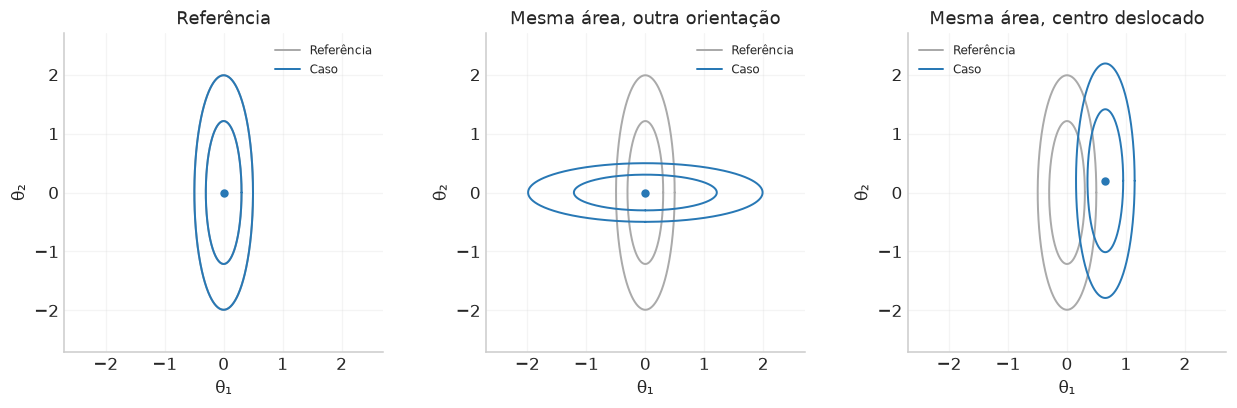

,Caso,"Área 95,45%",FoM isolada
0,Referência,3.10645,6.25
1,"Mesma área, outra orientação",3.10645,6.25
2,"Mesma área, centro deslocado",3.10645,6.25


In [3]:
C1=cov_elipse(.2,.8)
L1=np.linalg.solve(C1,np.eye(2))
P=np.eye(2)/9  # prior N(0, 3² I), própria e comum às comparações
fig,ax=plt.subplots(1,3,figsize=(11.5,3.6),constrained_layout=True)
casos_area=[('Referência',np.zeros(2),C1),('Mesma área, outra orientação',np.zeros(2),cov_elipse(.2,.8,np.pi/2)),
            ('Mesma área, centro deslocado',np.array([.65,.2]),C1)]
areas=[]
for a,(lab,mu,Ci) in zip(ax,casos_area):
    elipse(a,[0,0],C1,'#aaaaaa',label='Referência')
    elipse(a,mu,Ci,AZUL,label='Caso')
    a.scatter(*mu,color=AZUL,s=20)
    a.set(xlabel='θ₁',ylabel='θ₂',xlim=(-2.7,2.7),ylim=(-2.7,2.7),title=lab)
    a.set_aspect('equal');a.legend(fontsize=8)
    areas.append({'Caso':lab,'Área 95,45%':np.pi*stats.chi2.ppf(.9545,2)*np.sqrt(np.linalg.det(Ci)),
                  'FoM isolada':np.exp(-.5*logdet(Ci))})
figura(fig,'01_area_covariancia')
tabela(pd.DataFrame(areas),'area_fom')
verificar('Deslocar a média não altera FoM',np.allclose([a['FoM isolada'] for a in areas],areas[0]['FoM isolada']))

## 2. Kullback–Leibler: diferença como custo de usar outra distribuição

Para densidades normalizadas $p$ e $q$,
$$
D_{\rm KL}(p\|q)=\int p(\theta)\ln\frac{p(\theta)}{q(\theta)}\,d\theta.
$$
Sob $p$, o custo logarítmico médio de prever com $q$ é $\mathbb E_p[-\ln q]$. Usar $p$ no lugar de $q$ dá $\mathbb E_p[-\ln p]$; a diferença é a KL. Regiões frequentes sob $p$ pesam muito, sobretudo se $q$ lhes atribui densidade muito pequena.

A direção importa: trocar $p$ por $q$ troca a distribuição sob a qual fazemos a média. Se $q=0$ onde $p$ tem massa positiva, $D_{\rm KL}(p\|q)=+\infty$. Quando $p=q$, o logaritmo é zero. A desigualdade $\ln u\leq u-1$ mostra a não negatividade:
$$
-D_{\rm KL}(p\|q)=\mathbb E_p[\ln(q/p)]
\leq\mathbb E_p[q/p-1]=0,
$$
para suportes comuns; massa de $q$ fora do suporte de $p$ só torna a última esperança menor ou igual a zero.

KLD não é uma métrica: em geral não é simétrica e não satisfaz a desigualdade triangular. Somar as duas direções produz uma divergência simétrica, mas não resolve automaticamente a condição triangular.

Para posterior e prior,
$$
D_{\rm KL}[p(\theta\mid D)\|\pi(\theta)]
=\mathbb E_{\theta\mid D}[\ln\mathcal L(D\mid\theta)]-\ln Z.
$$
Essa identidade vem de $p/\pi=\mathcal L/Z$. Mede a atualização realizada com esses dados. Não é um teste de ausência de sistemáticas: uma atualização grande também pode vir de dados enviesados.

### 2.1 Derivação completa para gaussianas

Tome $p=N(m_p,V_p)$ e $q=N(m_q,V_q)$, em $k$ dimensões:
$$
\ln\frac pq=
\frac12\ln\frac{\det V_q}{\det V_p}
-\frac12(\theta-m_p)^TV_p^{-1}(\theta-m_p)
+\frac12(\theta-m_q)^TV_q^{-1}(\theta-m_q).
$$
Escreva $\theta-m_q=(\theta-m_p)+(m_p-m_q)$. A média do termo cruzado é zero, porque $\mathbb E_p[\theta-m_p]=0$. Para uma matriz $A$,
$$
\mathbb E_p[(\theta-m_p)^TA(\theta-m_p)]
=\sum_{ij}A_{ij}(V_p)_{ij}=\operatorname{tr}(AV_p).
$$
Assim, a primeira forma quadrática tem esperança $k$, e a segunda tem
$\operatorname{tr}(V_q^{-1}V_p)+(m_p-m_q)^TV_q^{-1}(m_p-m_q)$. Logo,
$$
\boxed{
D_{\rm KL}(p\|q)=\frac12\left[
\ln\frac{\det V_q}{\det V_p}-k+
\operatorname{tr}(V_q^{-1}V_p)+
(m_p-m_q)^TV_q^{-1}(m_p-m_q)
\right].}
$$
Há contribuições de **largura/forma** e de **deslocamento**, ponderadas pela distribuição de referência.

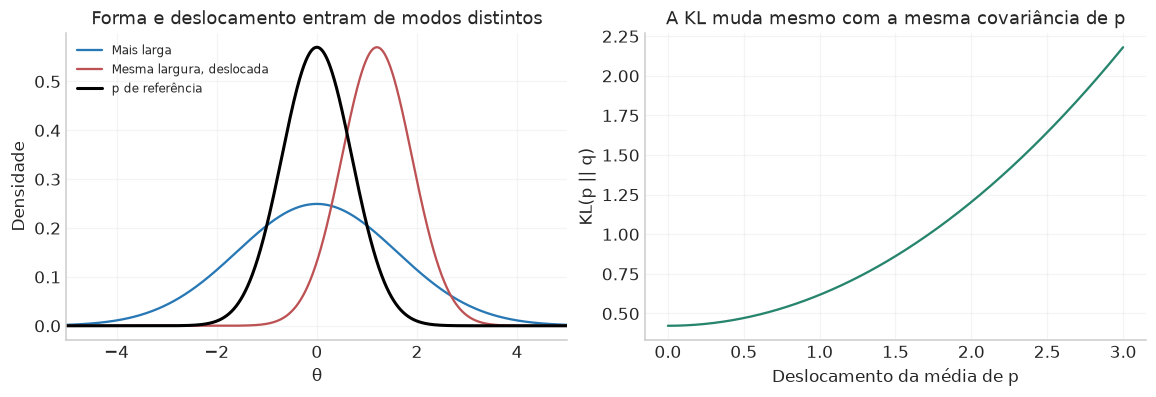

,q,KL(p||q),KL(q||p)
0,Mais larga,0.42238,1.28557
1,"Mesma largura, deslocada",1.46939,1.46939


In [4]:
xx_kl=np.linspace(-8,8,2401)
p_kl=stats.norm.pdf(xx_kl,0,.7)
fig,ax=plt.subplots(1,2,figsize=(10.4,3.5),constrained_layout=True)
regs_kl=[]
for mu,s,cor,lab in [(0.,1.6,AZUL,'Mais larga'),(1.2,.7,VERMELHO,'Mesma largura, deslocada')]:
    q=stats.norm.pdf(xx_kl,mu,s)
    ax[0].plot(xx_kl,q,color=cor,label=lab)
    pq=kl_gauss([0],np.array([[.7**2]]),[mu],np.array([[s*s]]))
    qp=kl_gauss([mu],np.array([[s*s]]),[0],np.array([[.7**2]]))
    regs_kl.append({'q':lab,'KL(p||q)':pq,'KL(q||p)':qp})
ax[0].plot(xx_kl,p_kl,color='black',lw=2,label='p de referência')
ax[0].set(xlim=(-5,5),xlabel='θ',ylabel='Densidade',title='Forma e deslocamento entram de modos distintos');ax[0].legend(fontsize=8)
deslocs=np.linspace(0,3,300)
kl_desloc=[kl_gauss([d],np.array([[.7**2]]),[0],np.array([[1.6**2]])) for d in deslocs]
ax[1].plot(deslocs,kl_desloc,color=VERDE)
ax[1].set(xlabel='Deslocamento da média de p',ylabel='KL(p || q)',title='A KL muda mesmo com a mesma covariância de p')
figura(fig,'02_kl_intuicao')
tabela(pd.DataFrame(regs_kl),'kl_assimetria')
verificar('KLD é zero para gaussianas iguais',np.isclose(kl_gauss([0],np.eye(1),[0],np.eye(1)),0))
verificar('KL gaussiana e integral direta concordam',
    np.isclose(integrate.trapezoid(p_kl*(stats.norm.logpdf(xx_kl,0,.7)-stats.norm.logpdf(xx_kl,0,1.6)),x=xx_kl),regs_kl[0]['KL(p||q)'],rtol=1e-7))

### 2.2 A fórmula do slide 114: o termo de média tem uma hipótese

Use prior $\pi=N(0,P^{-1})$ e posterior $p=N(m,F^{-1})$. A fórmula geral fica
$$
D_{\rm KL}(p\|\pi)=
\frac12\left[\ln\frac{\det F}{\det P}-k+
\operatorname{tr}(PF^{-1})+m^TPm\right].
$$
A expressão do slide 114 corresponde a $m=0$, isto é, centros alinhados:
$$
D_0(F)=\frac12\left[\ln\frac{\det F}{\det P}
-\operatorname{tr}(I-PF^{-1})\right].
$$
É essa quantidade dependente das precisões que usaremos para a FoM dos slides. Se o posterior estiver deslocado, o termo $m^TPm/2$ precisa voltar. Usá-lo como “melhoria” de um experimento pode recompensar um viés, justamente o que a análise de robustez procura separar.

Outra operação é a média do ganho sobre dados gerados pela **prior preditiva**. Em um modelo linear gaussiano de precisão fixa,
$$
\mathbb E_D[D_{\rm KL}(p(\theta\mid D)\|\pi)]
=\frac12\ln\frac{\det F}{\det P}.
$$
Isso ocorre porque $\mathbb E_D[m^TPm]=k-\operatorname{tr}(PF^{-1})$. A média usa tanto $\theta$ sorteado da prior quanto o ruído dos dados. Ela não é a mesma coisa que fixar o centro do posterior no centro da prior.

In [5]:
F_info=L1+P
def ganho_centrado(F,P):
    k=len(P)
    return .5*(logdet(F)-logdet(P)-k+np.trace(np.linalg.solve(F,P)))
rng_info=np.random.default_rng(2701)
Vp=np.linalg.solve(P,np.eye(2));Vpost=np.linalg.solve(F_info,np.eye(2))
theta_info=rng_info.multivariate_normal([0,0],Vp,size=30000)
dados_info=theta_info+rng_info.multivariate_normal([0,0],C1,size=len(theta_info))
medias_info=np.linalg.solve(F_info,L1@dados_info.T).T
ganhos=ganho_centrado(F_info,P)+.5*np.einsum('ni,ij,nj->n',medias_info,P,medias_info)
esperado_info=.5*(logdet(F_info)-logdet(P))
tabela(pd.DataFrame({'Operação':['Centros alinhados (slide 114)','Média prior preditiva: analítica','Média prior preditiva: simulada'],
    'Ganho em nats':[ganho_centrado(F_info,P),esperado_info,ganhos.mean()]}),'ganho_informacao')
verificar('Média do ganho corresponde à informação mútua gaussiana',
    abs(ganhos.mean()-esperado_info)<5*ganhos.std(ddof=1)/np.sqrt(len(ganhos)))

,Operação,Ganho em nats
0,Centros alinhados (slide 114),3.10178
1,Média prior preditiva: analítica,4.06637
2,Média prior preditiva: simulada,4.06214


## 3. Slide 115: os dois casos da FoM estatística normalizada

Suponha sondas independentes **condicionalmente aos parâmetros**, likelihoods gaussianas de precisões $L_1,L_2$ e uma única prior de precisão $P$:
$$
F=L_1+L_2+P.
$$
A referência é uma nova observação **independente**, com a mesma precisão da sonda 1: $L_2=L_1$. Então
$$
F_\star=2L_1+P.
$$
Repetir o experimento não significa contar os mesmos dados duas vezes. Dados compartilhados exigem uma likelihood conjunta com suas correlações.

O slide usa a **diferença** dos ganhos, depois a exponencia:
$$
S=\exp[D_0(F)-D_0(F_\star)].
$$
Substituindo as duas expressões, os termos $-k$ e $-\ln\det P$ cancelam:
$$
\boxed{
S=\sqrt{\frac{\det(L_1+L_2+P)}{\det(2L_1+P)}}
\exp\left\{\frac12\operatorname{tr}
\left[P\left((L_1+L_2+P)^{-1}-(2L_1+P)^{-1}\right)\right]\right\}.}
$$

**Caso 1:** uma sonda 2 independente com $L_2$ diferente. Direções complementares podem produzir $S>1$: a combinação restringe um volume menor que uma repetição de igual precisão.

**Caso 2:** $L_2=L_1$. Numerador e denominador coincidem, e a diferença das inversas é zero: $S=1$.

Uma sonda independente muito fraca pode dar $S<1$, porque o benchmark é uma repetição informativa. Isso não é informação negativa: é desempenho menor **em relação à referência**.

No limite de prior larga, mantendo-a própria em qualquer cálculo de evidência,
$$
S\longrightarrow
\sqrt{\frac{\det(L_1+L_2)}{\det(2L_1)}}.
$$
A dependência da prior se reduz, mas o cancelamento em prior finita não é total.

,Caso,S,FoM likelihood isolada 2,FoM posterior combinada
0,Caso 1: complementar,2.06526,6.250,26.67361
1,Caso 2: repetição,1.00000,6.250,12.73441
2,Independente e fraca,0.56610,0.625,7.10806


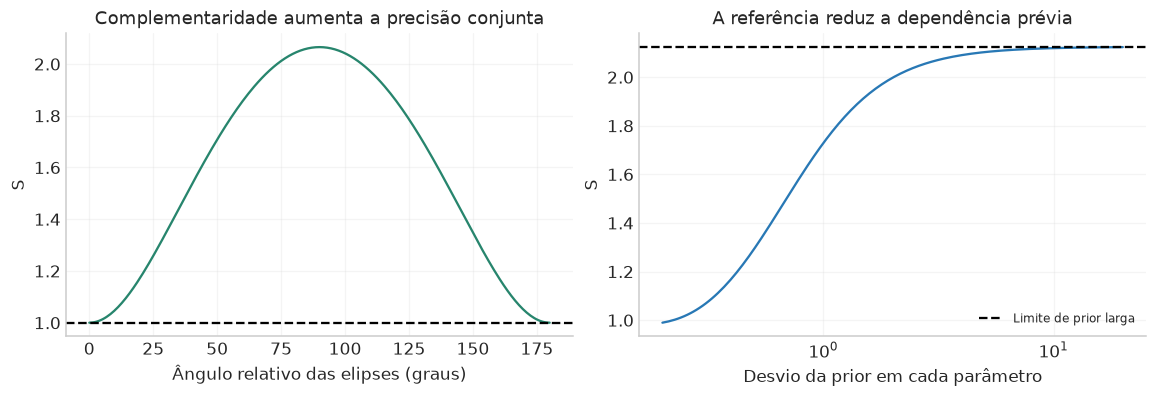

In [6]:
def logS(L1,L2,P):
    F=L1+L2+P;Fstar=2*L1+P
    return .5*(logdet(F)-logdet(Fstar)+
        np.trace(P@(np.linalg.solve(F,np.eye(len(P)))-np.linalg.solve(Fstar,np.eye(len(P))))))
L2_complementar=np.linalg.solve(cov_elipse(.2,.8,np.pi/2),np.eye(2))
comparacoes_S=[('Caso 1: complementar',L2_complementar),('Caso 2: repetição',L1),('Independente e fraca',.1*L1)]
tabela(pd.DataFrame([{'Caso':lab,'S':np.exp(logS(L1,L2,P)),
    'FoM likelihood isolada 2':np.exp(.5*logdet(L2)),
    'FoM posterior combinada':np.exp(.5*logdet(L1+L2+P))} for lab,L2 in comparacoes_S]),'slide115_casos')
angulos=np.linspace(0,np.pi,241)
val_S=[]
for ang in angulos:
    L2=np.linalg.solve(cov_elipse(.2,.8,ang),np.eye(2))
    val_S.append(np.exp(logS(L1,L2,P)))
fig,ax=plt.subplots(1,2,figsize=(10.4,3.5),constrained_layout=True)
ax[0].plot(angulos*180/np.pi,val_S,color=VERDE)
ax[0].axhline(1,color='black',ls='--')
ax[0].set(xlabel='Ângulo relativo das elipses (graus)',ylabel='S',title='Complementaridade aumenta a precisão conjunta')
tau_prior=np.geomspace(.2,20,150)
val_prior=[np.exp(logS(L1,L2_complementar,np.eye(2)/t**2)) for t in tau_prior]
ax[1].semilogx(tau_prior,val_prior,color=AZUL)
limite_S=np.exp(.5*(logdet(L1+L2_complementar)-logdet(2*L1)))
ax[1].axhline(limite_S,color='black',ls='--',label='Limite de prior larga')
ax[1].set(xlabel='Desvio da prior em cada parâmetro',ylabel='S',title='A referência reduz a dependência prévia');ax[1].legend(fontsize=8)
figura(fig,'03_slide115_fom')
verificar('Repetição independente define S=1',np.isclose(logS(L1,L1,P),0))
verificar('S coincide com diferença exponenciada das KL centradas',
    np.isclose(logS(L1,L2_complementar,P),ganho_centrado(L1+L2_complementar+P,P)-ganho_centrado(2*L1+P,P)))

## 4. A conta que sustenta as duas robustezes: a evidência gaussiana

Vamos abrir uma única derivação e reutilizá-la. Seja
$$
\mathcal L(\theta)=\mathcal L_{\max}
\exp[-\tfrac12(\theta-\hat\theta)^TL(\theta-\hat\theta)],
$$
e prior própria
$$
\pi(\theta)=\frac{\sqrt{\det P}}{(2\pi)^{k/2}}
\exp[-\tfrac12(\theta-m_0)^TP(\theta-m_0)].
$$
Defina
$$
F=L+P,\quad h=L\hat\theta+Pm_0,\quad
m=F^{-1}h,\quad c=\hat\theta^TL\hat\theta+m_0^TPm_0.
$$
Somando os expoentes e completando o quadrado,
$$
(\theta-\hat\theta)^TL(\theta-\hat\theta)
+(\theta-m_0)^TP(\theta-m_0)
=\theta^TF\theta-2h^T\theta+c
=(\theta-m)^TF(\theta-m)+c-h^TF^{-1}h.
$$
A integral em $\theta$ é a integral de Laplace do notebook anterior; aqui ela é **exata**, pois o expoente já é quadrático:
$$
\boxed{Z=\mathcal L_{\max}
\sqrt{\frac{\det P}{\det F}}\,
\exp[-\tfrac12(c-h^TF^{-1}h)].}
$$
O fator de volume $\sqrt{\det P/\det F}$ é a razão entre volume posterior e volume prévio, segundo a convenção gaussiana. O fator exponencial mede a separação entre o centro prévio e o centro da likelihood.

Também podemos escrever, para $L$ e $P$ invertíveis,
$$
c-h^TF^{-1}h
=(\hat\theta-m_0)^T(L^{-1}+P^{-1})^{-1}(\hat\theta-m_0).
$$
É a penalização de deslocamento, às vezes chamada fator de bias nesse contexto. Ela não demonstra que os dados têm um erro sistemático: uma realização estatística ou uma prior inadequada também pode gerar esse deslocamento.

Se $P\ll L$ **e** a prior varia pouco na região ajustada,
$$
Z\simeq\mathcal L_{\max}\sqrt{\det P/\det L}.
$$
Uma prior larga comparada à largura da likelihood ainda pode penalizar fortemente um máximo extremamente distante de seu centro. Precisamos verificar as duas condições. Uma prior imprópria de amplitude arbitrária não fornece evidências comparáveis.

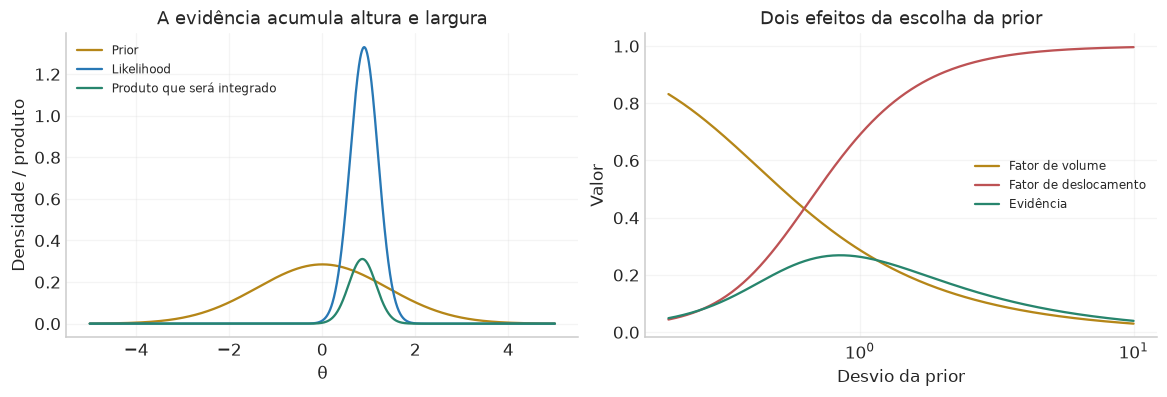

In [7]:
def evid_gauss(mu,L,P,m0=None,logLmax=0.):
    mu=np.atleast_1d(mu).astype(float);k=len(mu)
    m0=np.zeros(k) if m0 is None else np.asarray(m0,float)
    F=L+P;h=L@mu+P@m0
    media=np.linalg.solve(F,h)
    c=mu@L@mu+m0@P@m0
    penalidade=c-h@media
    log_occam=.5*(logdet(P)-logdet(F))
    return {'logZ':logLmax+log_occam-.5*penalidade,'media':media,
        'cov':cov_de_precisao(F),'F':F,'logOccam':log_occam,'logDeslocamento':-.5*penalidade}

# Uma medida vetorial µ é gerada como N(θ, C_like); a prior é N(m0,V_prior).
mu_e=np.array([.5,-.2]);Ce=np.array([[.3**2,.025],[.025,.5**2]])
Le=np.linalg.solve(Ce,np.eye(2));m0_e=np.array([.1,.1])
ev=evid_gauss(mu_e,Le,P,m0_e,logLmax=-np.log(2*np.pi)-.5*logdet(Ce))
logZ_pred=stats.multivariate_normal.logpdf(mu_e,mean=m0_e,cov=Ce+np.linalg.solve(P,np.eye(2)))
verificar('Evidência por completar quadrado coincide com prior preditiva',np.isclose(ev['logZ'],logZ_pred))

xx_e=np.linspace(-5,5,1601);mu_e1=.9;se1=.3;tp1=1.4
e1=evid_gauss([mu_e1],np.array([[1/se1**2]]),np.array([[1/tp1**2]]),
    logLmax=-.5*np.log(2*np.pi*se1**2))
integrando=stats.norm.pdf(mu_e1,loc=xx_e,scale=se1)*stats.norm.pdf(xx_e,0,tp1)
valquad=integrate.quad(lambda t:stats.norm.pdf(mu_e1,t,se1)*stats.norm.pdf(t,0,tp1),-np.inf,np.inf)[0]
verificar('Evidência gaussiana e quadratura direta coincidem',np.isclose(np.exp(e1['logZ']),valquad))
fig,ax=plt.subplots(1,2,figsize=(10.5,3.5),constrained_layout=True)
ax[0].plot(xx_e,stats.norm.pdf(xx_e,0,tp1),color=OURO,label='Prior')
ax[0].plot(xx_e,stats.norm.pdf(mu_e1,xx_e,se1),color=AZUL,label='Likelihood')
ax[0].plot(xx_e,integrando,color=VERDE,label='Produto que será integrado')
ax[0].set(xlabel='θ',ylabel='Densidade / produto',title='A evidência acumula altura e largura');ax[0].legend(fontsize=8)
ts=np.geomspace(.2,10,250);occ=[];biasf=[];ze=[]
for t in ts:
    z=evid_gauss([mu_e1],np.array([[1/se1**2]]),np.array([[1/t**2]]),logLmax=-.5*np.log(2*np.pi*se1**2))
    occ.append(np.exp(z['logOccam']));biasf.append(np.exp(z['logDeslocamento']));ze.append(np.exp(z['logZ']))
ax[1].semilogx(ts,occ,color=OURO,label='Fator de volume')
ax[1].semilogx(ts,biasf,color=VERMELHO,label='Fator de deslocamento')
ax[1].semilogx(ts,ze,color=VERDE,label='Evidência')
ax[1].set(xlabel='Desvio da prior',ylabel='Valor',title='Dois efeitos da escolha da prior');ax[1].legend(fontsize=8)
figura(fig,'04_evidencia_fatores')

## 5. Robustez externa: quais hipóteses o fator de Bayes compara?

Sejam $D_1,D_2$ resultados de duas sondas. A comparação básica é:

- $H_c$: um **mesmo** vetor $\theta$ descreve as duas sondas.
- $H_s$: há vetores independentes $\theta_1,\theta_2$, com priors especificadas, para descrever cada sonda.

As funções físicas podem ter a mesma forma sob $H_s$; o que muda é permitir parâmetros diferentes. Essa alternativa detecta a necessidade de uma descrição mais flexível, sem identificar automaticamente a causa física.

Com independência dos ruídos condicionada aos parâmetros,
$$
Z_c=\int\mathcal L_1(\theta)\mathcal L_2(\theta)\pi(\theta)d\theta,
$$
$$
Z_s=\int\mathcal L_1(\theta_1)\pi(\theta_1)d\theta_1
\int\mathcal L_2(\theta_2)\pi(\theta_2)d\theta_2
=Z_1Z_2.
$$
**É sob a hipótese de parâmetros separados que a evidência se fatoriza.** Ter o mesmo modelo funcional e ruídos independentes não autoriza fatorizar a evidência quando o parâmetro é compartilhado: a integral comum acopla os dados. Essa distinção é essencial ao interpretar a frase introdutória do slide 134.

O fator de Bayes é
$$
\boxed{\mathcal B=\frac{Z_c}{Z_1Z_2}.}
$$
As odds posteriores são $\mathcal B$ vezes as odds prévias dos modelos. Só com probabilidades prévias iguais temos
$P(H_c\mid D)=\mathcal B/(1+\mathcal B)$.

### 5.1 A interpretação preditiva do slide 118

Pela regra do produto,
$$
\mathcal B=\frac{p(D_2\mid D_1,H_c)}{p(D_2\mid H_s)},
\quad
p(D_2\mid D_1,H_c)=
\int\mathcal L_2(\theta)p(\theta\mid D_1)d\theta.
$$
O numerador prevê a **segunda** sonda usando o que a primeira ensinou. O denominador prevê a segunda usando a prior independente da hipótese separada. Perguntamos se conhecer $D_1$ ajudou ou atrapalhou a prever $D_2$.

Se as duas análises usaram a mesma prior, outra identidade útil é
$$
\mathcal B=\int\frac{p(\theta\mid D_1)p(\theta\mid D_2)}{\pi(\theta)}d\theta.
$$
Basta substituir $p_i=\mathcal L_i\pi/Z_i$. O denominador remove a cópia extra da prior. Assim, multiplicar diretamente dois posteriors sem dividir pela prior comum contaria essa informação duas vezes.

### 5.2 Abrir a fórmula gaussiana dos slides 118–120

No restante desta seção, a prior está centrada em zero. Denote os máximos das likelihoods por $\mu_i$. Então
$$
F_i=L_i+P,\quad m_i=F_i^{-1}L_i\mu_i,
\qquad F=L_1+L_2+P,\quad
m=F^{-1}(L_1\mu_1+L_2\mu_2).
$$
Aplicando a evidência da seção 4 separadamente e ao conjunto, os fatores $\mathcal L_{\max,1}\mathcal L_{\max,2}$ cancelam no quociente. Os termos $\mu_i^TL_i\mu_i$ também cancelam, deixando
$$
\boxed{
\ln\mathcal B=
\frac12\ln\frac{\det F_1\det F_2}{\det F\det P}
+\frac12\left[m^TFm-m_1^TF_1m_1-m_2^TF_2m_2\right].
}
$$
O primeiro bloco envolve volumes e a penalização por dar liberdade a dois vetores em vez de um. O segundo envolve seus centros. Na configuração de bias do próximo bloco, ele se torna uma penalização não negativa no expoente. A prior continua presente: evidências comparam modelos probabilísticos completos, inclusive seus volumes prévios.

In [8]:
def robust_externa(mu1,L1,mu2,L2,P):
    mu1,mu2=np.asarray(mu1,float),np.asarray(mu2,float);k=len(mu1)
    lmax1=.5*(logdet(L1)-k*np.log(2*np.pi))
    lmax2=.5*(logdet(L2)-k*np.log(2*np.pi))
    e1=evid_gauss(mu1,L1,P,logLmax=lmax1)
    e2=evid_gauss(mu2,L2,P,logLmax=lmax2)
    F=L1+L2+P;h=L1@mu1+L2@mu2
    m=np.linalg.solve(F,h);c=mu1@L1@mu1+mu2@L2@mu2
    logZc=lmax1+lmax2+.5*(logdet(P)-logdet(F))-.5*(c-h@m)
    logB=logZc-e1['logZ']-e2['logZ']
    occ=.5*(logdet(e1['F'])+logdet(e2['F'])-logdet(F)-logdet(P))
    centros=.5*(m@F@m-e1['media']@e1['F']@e1['media']-e2['media']@e2['F']@e2['media'])
    return {'logB':logB,'logZc':logZc,'e1':e1,'e2':e2,'media':m,
        'cov':cov_de_precisao(F),'F':F,'volume':occ,'centros':centros}

# A própria regra preditiva verifica o cálculo de evidências.
mu1_t,mu2_t=np.array([.1,-.2]),np.array([.6,.1])
L2_t=np.linalg.solve(cov_elipse(.25,.6,.6),np.eye(2))
ext_t=robust_externa(mu1_t,L1,mu2_t,L2_t,P)
logpred=stats.multivariate_normal.logpdf(mu2_t,mean=ext_t['e1']['media'],
    cov=cov_de_precisao(L2_t)+ext_t['e1']['cov'])
logpriorpred=stats.multivariate_normal.logpdf(mu2_t,mean=[0,0],
    cov=cov_de_precisao(L2_t)+cov_de_precisao(P))
verificar('Bayes factor e quociente preditivo coincidem',np.isclose(ext_t['logB'],logpred-logpriorpred))
verificar('Decomposição entre volumes e centros',np.isclose(ext_t['logB'],ext_t['volume']+ext_t['centros']))
tabela(pd.DataFrame({'Método':['log Zc − log Z1 − log Z2','log preditiva posterior − log preditiva prévia'],
    'log B':[ext_t['logB'],logpred-logpriorpred]}),'externa_preditiva')

,Método,log B
0,log Zc − log Z1 − log Z2,2.28469
1,log preditiva posterior − log preditiva prévia,2.28469


## 6. Um experimento preciso pode ser vulnerável a bias

Para um forecast, coloque o valor verdadeiro na origem e suponha que a sonda 1 seja não enviesada: $\mu_1=0$. A sonda 2 sofre um deslocamento previsto $b$: $\mu_2=b$. Estamos isolando um bias sistemático; não sorteamos aqui as flutuações de realização de cada experimento.

As médias posteriores são
$$
m_1=0,\qquad m_2=F_2^{-1}L_2b,\qquad m=F^{-1}L_2b.
$$
A prior pode puxar $m_2$ para a origem; por isso a média posterior e o máximo da likelihood deslocada são objetos diferentes.

Substitua essas expressões no termo de centros:
$$
m^TFm-m_2^TF_2m_2
=b^TL_2F^{-1}L_2b-b^TL_2F_2^{-1}L_2b.
$$
Portanto,
$$
\boxed{\ln\mathcal B=\mathcal R_0-\frac12b^TK_b b,}
\quad
K_b=L_2(F_2^{-1}-F^{-1})L_2,
$$
$$
\mathcal R_0=\frac12\ln\frac{\det F_1\det F_2}{\det F\det P}.
$$
Como $F=F_2+L_1$, sua inversa é menor ou igual a $F_2^{-1}$ no sentido de formas quadráticas; logo $K_b$ é semidefinida positiva. O deslocamento reduz o fator de Bayes nessa configuração.

$b$ não é apenas um comprimento: sua **direção** importa. Um mesmo deslocamento pode ficar dentro de uma direção de grande incerteza ou atravessar uma direção já muito bem medida.

### 6.1 Normalização e o que os números significam

Para a repetição independente sem bias,
$$
\mathcal B_\star=
\frac{\det(L_1+P)}{\sqrt{\det(2L_1+P)\det P}},
\qquad R_N=\mathcal B/\mathcal B_\star.
$$
$R_N=1$ é o benchmark do slide 123, não uma probabilidade de ausência de sistemáticas. Uma sonda pouco informativa pode concordar facilmente com outra; precisamos examinar $S$ junto com a robustez.

Os slides 124–125 também mostram uma robustez média sobre intensidades do bias. Uma forma transparente de reproduzi-la é escrever $b_{\rm real}=\xi b$, $\xi\sim N(0,1)$, com precisões mantidas fixas. Se $q_b=b^TK_b b$,
$$
\langle R_N\rangle
=e^{\mathcal R_0-\ln\mathcal B_\star}
\int \frac{e^{-\xi^2/2}}{\sqrt{2\pi}}e^{-q_b\xi^2/2}d\xi
=\frac{e^{\mathcal R_0-\ln\mathcal B_\star}}{\sqrt{1+q_b}}.
$$
A média é uma escolha de distribuição para os possíveis biases. Se essa distribuição mudar, a média muda. O produto $S\langle R_N\rangle$ é uma FoM combinada possível, sem status de probabilidade.

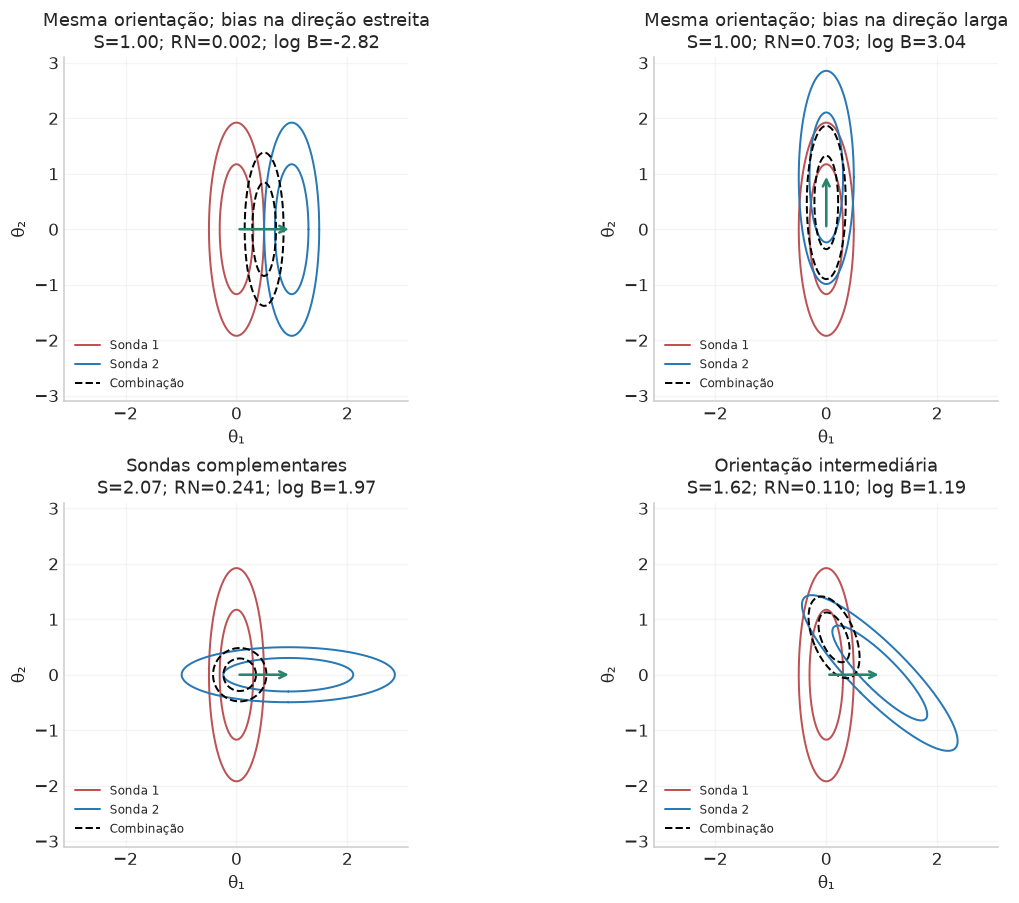

,Caso,S,log B,RN,RN médio,S × RN médio,"P(Hc|D), priors iguais"
0,Mesma orientação; bias na direção estreita,1.0000,-2.8173,0.0020,0.2730,0.2730,0.0564
1,Mesma orientação; bias na direção larga,1.0000,3.0390,0.7032,0.7660,0.7660,0.9543
2,Sondas complementares,2.0653,1.9682,0.2410,0.3103,0.6408,0.8774
3,Orientação intermediária,1.6225,1.1877,0.1104,0.2899,0.4704,0.7663


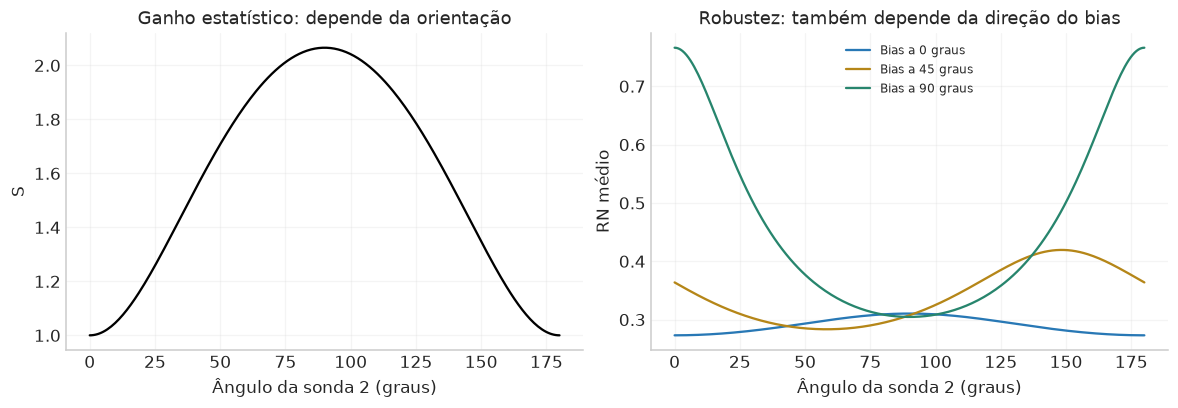

In [10]:
def metricas_bias(L1,L2,P,b):
    zero=np.zeros(len(P));r0=robust_externa(zero,L1,zero,L2,P)['logB']
    ref=robust_externa(zero,L1,zero,L1,P)['logB']
    F2=L2+P;F=L1+L2+P
    Kb=L2@(cov_de_precisao(F2)-cov_de_precisao(F))@L2
    q=float(np.asarray(b)@Kb@np.asarray(b))
    return {'logB':r0-.5*q,'RN':np.exp(r0-.5*q-ref),
        'RNmedio':np.exp(r0-ref)/np.sqrt(1+q),'S':np.exp(logS(L1,L2,P)),
        'Kb':Kb,'q':q,'r0':r0}
casos_ext=[
    ('Mesma orientação; bias na direção estreita',0.,np.array([1.,0.])),
    ('Mesma orientação; bias na direção larga',0.,np.array([0.,1.])),
    ('Sondas complementares',np.pi/2,np.array([1.,0.])),
    ('Orientação intermediária',np.pi/4,np.array([1.,0.]))]
fig,ax=plt.subplots(2,2,figsize=(10.7,8.1),constrained_layout=True)
linhas_ext=[]
for a,(lab,ang,b) in zip(ax.ravel(),casos_ext):
    L2=np.linalg.solve(cov_elipse(.2,.8,ang),np.eye(2))
    rr=robust_externa([0,0],L1,b,L2,P);met=metricas_bias(L1,L2,P,b)
    elipse(a,rr['e1']['media'],rr['e1']['cov'],VERMELHO,label='Sonda 1')
    elipse(a,rr['e2']['media'],rr['e2']['cov'],AZUL,label='Sonda 2')
    elipse(a,rr['media'],rr['cov'],'black',label='Combinação',ls='--')
    a.annotate('',xy=b,xytext=(0,0),arrowprops={'arrowstyle':'->','color':VERDE,'lw':1.7})
    a.set(xlabel='θ₁',ylabel='θ₂',xlim=(-3.1,3.1),ylim=(-3.1,3.1),
        title=lab+f"\nS={met['S']:.2f}; RN={met['RN']:.3f}; log B={rr['logB']:.2f}")
    a.set_aspect('equal');a.legend(fontsize=8,loc='lower left')
    linhas_ext.append({'Caso':lab,'S':met['S'],'log B':rr['logB'],'RN':met['RN'],
        'RN médio':met['RNmedio'],'S × RN médio':met['S']*met['RNmedio'],
        'P(Hc|D), priors iguais':special.expit(rr['logB'])})
    verificar(f'Penalização de bias reproduz evidências: {lab}',np.isclose(rr['logB'],met['logB']))
figura(fig,'05_externa_quatro_casos')
tabela(pd.DataFrame(linhas_ext),'externa_casos',casas=4)

fig,ax=plt.subplots(1,2,figsize=(10.6,3.6),constrained_layout=True)
ax[0].plot(angulos*180/np.pi,val_S,color='black')
ax[0].set(xlabel='Ângulo da sonda 2 (graus)',ylabel='S',title='Ganho estatístico: depende da orientação')
for ang_b,cor in [(0,AZUL),(np.pi/4,OURO),(np.pi/2,VERDE)]:
    b=np.array([np.cos(ang_b),np.sin(ang_b)])
    curva=[]
    for ang in angulos:
        L2=np.linalg.solve(cov_elipse(.2,.8,ang),np.eye(2))
        curva.append(metricas_bias(L1,L2,P,b)['RNmedio'])
    ax[1].plot(angulos*180/np.pi,curva,color=cor,label=f'Bias a {ang_b*180/np.pi:.0f} graus')
ax[1].set(xlabel='Ângulo da sonda 2 (graus)',ylabel='RN médio',title='Robustez: também depende da direção do bias');ax[1].legend(fontsize=8)
figura(fig,'06_externa_orientacao_bias')
verificar('Repetição não enviesada define RN=1',np.isclose(metricas_bias(L1,L1,P,[0,0])['RN'],1))

## 7. Slide 127: JSD versus KLD

Uma simetrização por soma,
$D_{\rm KL}(p\|q)+D_{\rm KL}(q\|p)$, ainda pode divergir quando os suportes diferem. A **Jensen–Shannon divergence** cria antes a mistura
$$
m(\theta)=\tfrac12p(\theta)+\tfrac12q(\theta),
$$
e compara cada distribuição com ela:
$$
\boxed{
\operatorname{JSD}(p,q)=
\tfrac12D_{\rm KL}(p\|m)+\tfrac12D_{\rm KL}(q\|m).
}
$$
A mistura não é o produto dos posteriors de duas sondas nem sua combinação bayesiana: ela significa sortear uma das duas distribuições com pesos iguais e depois sortear $\theta$.

Como $m\geq p/2$ e $m\geq q/2$, os logaritmos das razões são limitados superiormente por $\ln2$. Cada KL é não negativa, logo
$$
0\leq\operatorname{JSD}(p,q)\leq\ln2.
$$
Se os suportes são disjuntos, a observação identifica perfeitamente de qual componente veio e JSD atinge $\ln2$. Se são iguais, JSD é zero. Também podemos escrever
$$
\operatorname{JSD}(p,q)=H(m)-\tfrac12H(p)-\tfrac12H(q),
$$
quando essas entropias são finitas. Ela mede a informação sobre o rótulo do componente contida em uma observação da mistura.

O caráter limitado é útil para comparar distribuições separadas, mas causa **saturação**: duas distribuições já praticamente distinguíveis têm JSD perto de $\ln2$ mesmo que se afastem ainda mais. KLD continua penalizando atribuir densidade minúscula a regiões relevantes sob a referência.

### 7.1 Dois experimentos didáticos

Primeiro, compare $N(0,1)$ com $N(\delta,1)$. A KL é $\delta^2/2$ nas duas direções. JSD será calculada por integração, sem supor que a mistura é gaussiana: ela não é, em geral.

Segundo, considere duas distribuições em apenas duas categorias: $(1,0)$ e $(0,1)$. As duas KL são infinitas, enquanto JSD é $\ln2$. Não somaremos pequenos números arbitrários aos zeros para esconder essa diferença de suporte.

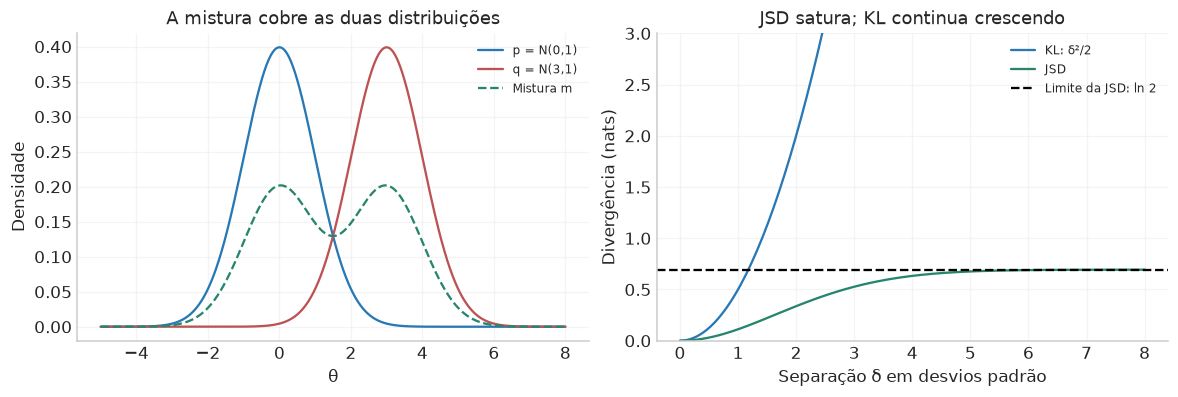

,Caso,KL(p||q),KL(q||p),JSD
0,Iguais,0.00000,0.00000,0.00000
1,"Diferentes, suporte comum",1.14573,1.36274,0.27540
2,Suportes disjuntos,inf,inf,0.69315


In [11]:
nodes_gh,weights_gh=np.polynomial.hermite.hermgauss(100)
def js_gauss_1d(mu1,s1,mu2,s2):
    # Integral de cada log-razão sob a sua própria gaussiana.
    # E_N(µ,s²)[f] = sum w_j f(µ+sqrt(2)s z_j) / sqrt(pi).
    x1=mu1+np.sqrt(2)*s1*nodes_gh
    x2=mu2+np.sqrt(2)*s2*nodes_gh
    lp1=stats.norm.logpdf(x1,mu1,s1);lq1=stats.norm.logpdf(x1,mu2,s2)
    lp2=stats.norm.logpdf(x2,mu1,s1);lq2=stats.norm.logpdf(x2,mu2,s2)
    lm1=np.logaddexp(lp1,lq1)-np.log(2)
    lm2=np.logaddexp(lp2,lq2)-np.log(2)
    return .5*np.sum(weights_gh*((lp1-lm1)+(lq2-lm2)))/np.sqrt(np.pi)
dist_js=np.linspace(0,8,170)
js_vals=np.array([js_gauss_1d(0,1,d,1) for d in dist_js])
fig,ax=plt.subplots(1,2,figsize=(10.6,3.5),constrained_layout=True)
xx=np.linspace(-5,8,1500)
ax[0].plot(xx,stats.norm.pdf(xx,0,1),color=AZUL,label='p = N(0,1)')
ax[0].plot(xx,stats.norm.pdf(xx,3,1),color=VERMELHO,label='q = N(3,1)')
ax[0].plot(xx,.5*(stats.norm.pdf(xx,0,1)+stats.norm.pdf(xx,3,1)),'--',color=VERDE,label='Mistura m')
ax[0].set(xlabel='θ',ylabel='Densidade',title='A mistura cobre as duas distribuições');ax[0].legend(fontsize=8)
ax[1].plot(dist_js,dist_js**2/2,color=AZUL,label='KL: δ²/2')
ax[1].plot(dist_js,js_vals,color=VERDE,label='JSD')
ax[1].axhline(np.log(2),color='black',ls='--',label='Limite da JSD: ln 2')
ax[1].set(xlabel='Separação δ em desvios padrão',ylabel='Divergência (nats)',ylim=(0,3),title='JSD satura; KL continua crescendo');ax[1].legend(fontsize=8)
figura(fig,'07_jsd_kld')
casos_div=[('Iguais',np.array([.5,.5]),np.array([.5,.5])),
    ('Diferentes, suporte comum',np.array([.9,.1]),np.array([.2,.8])),
    ('Suportes disjuntos',np.array([1.,0.]),np.array([0.,1.]))]
tabela(pd.DataFrame([{'Caso':lab,'KL(p||q)':kl_discreta(p,q),'KL(q||p)':kl_discreta(q,p),
    'JSD':js_discreta(p,q)} for lab,p,q in casos_div]),'jsd_suportes')
verificar('JSD é limitada nos exemplos gaussianos',np.all(js_vals>=-1e-12) and np.all(js_vals<=np.log(2)+1e-9))
verificar('Suportes disjuntos dão JSD=ln 2',np.isclose(js_discreta([1,0],[0,1]),np.log(2)))
verificar('KL respeita diferença de suporte',np.isinf(kl_discreta([1,0],[0,1])))

### 7.2 O elo com a métrica de Fisher

Considere uma família regular de distribuições dos dados $p(x\mid\theta)$, com suporte fixo. Ao expandir
$$
D_{\rm KL}[p(x\mid\theta)\|p(x\mid\theta+d\theta)],
$$
o termo linear é $-\mathbb E_\theta[\partial_a\ln p]\,d\theta_a=0$, pela normalização da distribuição. O termo quadrático usa
$-\mathbb E_\theta[\partial_a\partial_b\ln p]=I_{ab}(\theta)$:
$$
D_{\rm KL}=\tfrac12d\theta^TI(\theta)d\theta+O(\|d\theta\|^3).
$$
É nesse sentido local que Fisher funciona como métrica no espaço de distribuições: atribui tamanho estatístico a uma pequena mudança de parâmetros. Aqui a variável aleatória integrada é o **dado** $x$, não um parâmetro sorteado de uma posterior.

Uma divergência quadrática não é necessariamente uma distância métrica global. Até o quadrado da distância euclidiana falha na desigualdade triangular. Para gaussianas 1D de mesma variância, KL entre médias é justamente proporcional a essa distância ao quadrado.

## 8. Slide 128: Bhattacharyya como sobreposição de amplitudes

Definimos o coeficiente
$$
BC(p,q)=\int\sqrt{p(\theta)q(\theta)}\,d\theta,
\qquad D_B(p,q)=-\ln BC(p,q).
$$
Pense em $\sqrt p$ e $\sqrt q$ como vetores de norma unitária no espaço de funções. Então $BC$ é seu produto interno, entre 0 e 1 por Cauchy–Schwarz. Ele vale 1 para distribuições iguais e 0 para suportes disjuntos. A exponencial $e^{-D_B}$ traduz a divergência de volta para uma sobreposição.

$D_B$ é simétrica, mas não é uma métrica. Para gaussianas de mesma variância $\sigma^2$,
$D_B=\delta^2/(8\sigma^2)$: entre médias 0 e 2, o valor é maior que a soma dos valores entre 0 e 1 e entre 1 e 2. A distância de Hellinger, relacionada por $H^2=1-BC$ nessa convenção, oferece outra maneira de usar essa sobreposição.

### 8.1 Abrir a integral de gaussianas multivariadas

Para $p=N(m_1,V_1)$ e $q=N(m_2,V_2)$,
$$
\sqrt{pq}=
\frac{\exp\{-\tfrac14[(\theta-m_1)^TV_1^{-1}(\theta-m_1)
+(\theta-m_2)^TV_2^{-1}(\theta-m_2)]\}}
{(2\pi)^{k/2}(\det V_1\det V_2)^{1/4}}.
$$
Defina
$$
A=\tfrac12(V_1^{-1}+V_2^{-1}),\quad
h=\tfrac12(V_1^{-1}m_1+V_2^{-1}m_2),\quad
c=\tfrac12(m_1^TV_1^{-1}m_1+m_2^TV_2^{-1}m_2).
$$
O expoente se torna
$-\tfrac12[(\theta-A^{-1}h)^TA(\theta-A^{-1}h)+c-h^TA^{-1}h]$.
A integral gaussiana dá
$$
BC=(\det V_1\det V_2)^{-1/4}(\det A)^{-1/2}
e^{-\frac12(c-h^TA^{-1}h)}.
$$
Com $\bar V=(V_1+V_2)/2$, temos
$A=V_1^{-1}\bar V V_2^{-1}$, portanto
$\det A=\det\bar V/(\det V_1\det V_2)$.
Completando o quadrado no termo restante,
$c-h^TA^{-1}h=\tfrac14(m_1-m_2)^T\bar V^{-1}(m_1-m_2)$.
Assim,
$$
\boxed{
D_B=
\underbrace{\tfrac18(m_1-m_2)^T\bar V^{-1}(m_1-m_2)}_{\text{separação das médias}}
+\underbrace{\tfrac12\ln\frac{\det\bar V}{\sqrt{\det V_1\det V_2}}}_{\text{diferença de covariâncias}}.
}
$$
O primeiro termo usa a distância de Mahalanobis ao quadrado com a covariância média; o segundo detecta diferenças de largura e orientação, mesmo com médias iguais. Ambos precisam ser considerados para comparar as distribuições.

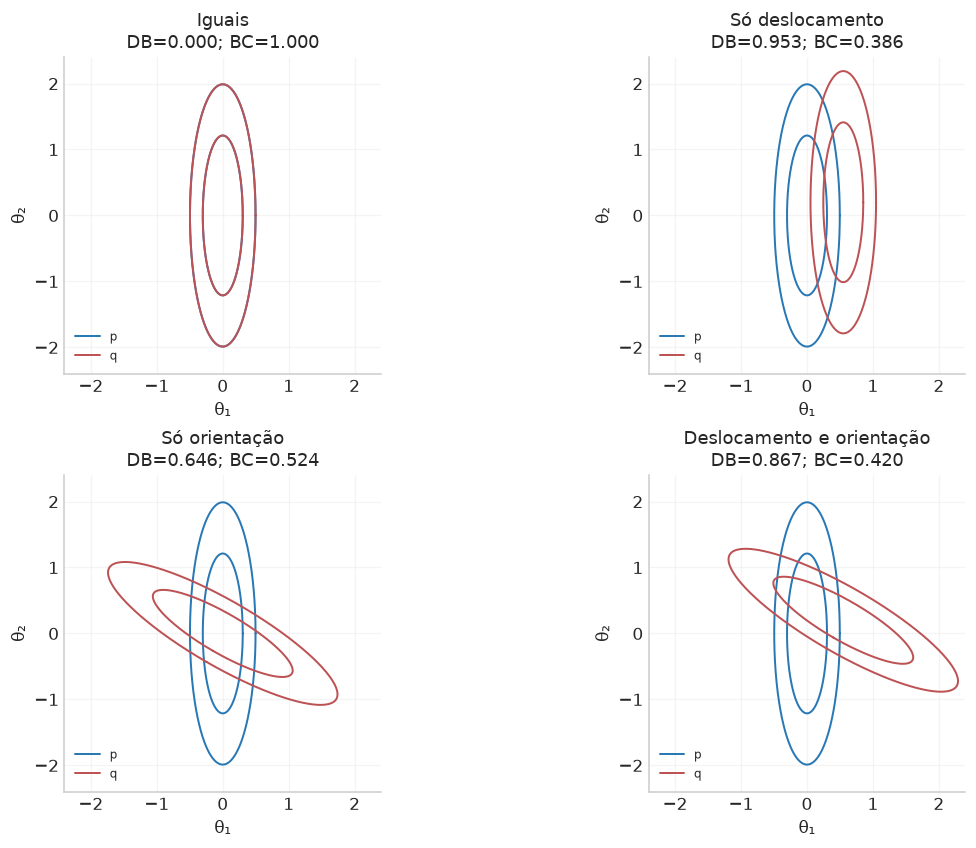

,Caso,D_B,BC,Deslocamento,Forma,BC por quadratura,KL(p||q),KL(q||p),JSD
0,Iguais,0.00000,1.00000,0.00000,0.00000,1.00000,0.00000,0.00000,0.00000
1,Só deslocamento,0.95312,0.38553,0.95312,0.00000,0.38553,3.81250,3.81250,0.48891
2,Só orientação,0.64554,0.52438,0.00000,0.64554,0.52438,5.27344,5.27344,0.36416
3,Deslocamento e orientação,0.86670,0.42034,0.22116,0.64554,0.42034,7.89517,9.08594,0.43268


In [13]:
grid_b=np.linspace(-6.5,6.5,701)
XB,YB=np.meshgrid(grid_b,grid_b,indexing='ij');pontos_b=np.stack([XB,YB],axis=-1)
def integral2(val):
    return integrate.trapezoid(integrate.trapezoid(val,x=grid_b,axis=1),x=grid_b)
casos_bhatt=[
    ('Iguais',np.zeros(2),C1),
    ('Só deslocamento',np.array([.55,.2]),C1),
    ('Só orientação',np.zeros(2),cov_elipse(.2,.8,np.pi/3)),
    ('Deslocamento e orientação',np.array([.55,.2]),cov_elipse(.2,.8,np.pi/3))]
lp=stats.multivariate_normal.logpdf(pontos_b,mean=[0,0],cov=C1)
fig,ax=plt.subplots(2,2,figsize=(10.6,7.6),constrained_layout=True)
regs_b=[]
for a,(lab,mq,Cq) in zip(ax.ravel(),casos_bhatt):
    info=bhatt_gauss(np.zeros(2),C1,mq,Cq)
    lq=stats.multivariate_normal.logpdf(pontos_b,mean=mq,cov=Cq)
    bc_quad=integral2(np.exp(.5*(lp+lq)))
    lm=np.logaddexp(lp,lq)-np.log(2)
    js_quad=.5*integral2(np.exp(lp)*(lp-lm)+np.exp(lq)*(lq-lm))
    elipse(a,[0,0],C1,AZUL,label='p')
    elipse(a,mq,Cq,VERMELHO,label='q')
    a.set(xlabel='θ₁',ylabel='θ₂',xlim=(-2.4,2.4),ylim=(-2.4,2.4),
        title=lab+f"\nDB={info['D_B']:.3f}; BC={info['BC']:.3f}")
    a.set_aspect('equal');a.legend(fontsize=8,loc='lower left')
    regs_b.append({'Caso':lab,**info,'BC por quadratura':bc_quad,
        'KL(p||q)':kl_gauss([0,0],C1,mq,Cq),'KL(q||p)':kl_gauss(mq,Cq,[0,0],C1),'JSD':js_quad})
    verificar(f'Bhattacharyya gaussiana e integração 2D: {lab}',np.isclose(info['BC'],bc_quad,rtol=1e-6,atol=1e-8))
figura(fig,'08_bhattacharyya_multivariada')
tabela(pd.DataFrame(regs_b),'bhattacharyya_gaussianas')

### 8.2 Qual comparação serve para qual pergunta?

| Quantidade | O que usa | Interpretação principal |
|---|---|---|
| KLD | Densidades e uma direção de expectativa | Custo relativo de representar $p$ por $q$ |
| JSD | Cada densidade comparada com a mistura | Distinguibilidade limitada, simétrica |
| Bhattacharyya | Sobreposição de $\sqrt p$ com $\sqrt q$ | Separação de massas e formas |
| Fator de Bayes comum/separado | Likelihoods, priors e hipóteses de parâmetros | Preferência relativa entre descrições dos dados |

Nenhuma divergência sozinha é uma probabilidade de sistemática ou um p-valor. Posteriors semelhantes também podem esconder um erro comum aos dois experimentos. Já uma prior forte pode aproximar dois posteriors que tinham likelihoods distintas. Por isso convém registrar quais distribuições foram comparadas e não converter arbitrariamente uma divergência em “número de sigmas”.

## 9. Robustez interna: a partição faz parte da pergunta

Agora há **um único catálogo** $D$, dividido em subconjuntos complementares $D_1,D_2$. Comparamos:

- $M_c$: todos os dados seguem um modelo com parâmetros comuns $\theta$.
- $M_s$: $D_1$ segue esse modelo com $\theta_1$, enquanto $D_2$ admite uma descrição separada com $\theta_2$.

Para o teste inicial usaremos a mesma forma funcional e a mesma prior própria para os dois vetores. Uma alternativa mais física, como um offset de calibração, virá no final.
$$
\mathcal B_{c,s}=
\frac{Z(D\mid M_c)}
{Z(D_1\mid M_c)Z(D_2\mid M_s)},
\qquad
\boxed{\mathcal R=\ln\mathcal B_{c,s}.}
$$
As evidências separadas se multiplicam porque os parâmetros são independentes sob a alternativa e os erros dos subconjuntos são independentes. Com covariâncias cruzadas, como na seção 6.2, precisamos reconstruir a likelihood conjunta sob ambas as hipóteses.

| Resultado | Fator de Bayes | Leitura para estes modelos e priors |
|---|---|---|
| $\mathcal R>0$ | $\mathcal B>1$ | A descrição comum é favorecida |
| $\mathcal R\simeq0$ | $\mathcal B\simeq1$ | Evidências semelhantes; pouca preferência |
| $\mathcal R<0$ | $\mathcal B<1$ | A descrição separada é favorecida |

Um valor grande e negativo motiva investigar heterogeneidade. Ele não prova quais dados estão errados ou se o modelo físico falhou. O caso $\mathcal R\simeq0$ também não comprova consistência: pode haver pouca informação para distinguir as hipóteses.

### 9.1 Dos slides 131–135 à fórmula com $\chi^2$

Com erros gaussianos conhecidos em $N$ dados,
$$
\mathcal L_{\max}=
(2\pi)^{-N/2}(\det C)^{-1/2}
\exp[-\tfrac12\hat\chi^2].
$$
Se o modelo é localmente linear nos parâmetros, a likelihood perto do máximo tem precisão $L$, e podemos usar a evidência da seção 4. Para prior larga e aproximadamente constante na região ajustada,
$$
Z\simeq
(2\pi)^{-N/2}(\det C)^{-1/2}
e^{-\hat\chi^2/2}\sqrt{\frac{\det P}{\det L}}.
$$
No quociente comum/separado, os fatores $(2\pi)^{-N/2}$ cancelam porque $N=N_1+N_2$. Com a mesma prior $P$ para cada vetor e erros independentes,
$\det C=\det C_1\det C_2$, de modo que
$$
\boxed{
\mathcal R\simeq
\underbrace{\frac12\ln\frac{\det L_1\det L_2}{\det L_{\rm tot}\det P}}_{\text{volume / Occam}}
-\underbrace{\frac12
\left(\hat\chi^2_{\rm tot}-\hat\chi^2_1-\hat\chi^2_2\right)}_{\text{ganho de ajuste ao separar}}.
}
$$
Isso corresponde a $\mathcal R_0+\frac12\ln(\det L_1\det L_2/\det L_{\rm tot})-\Delta\chi^2/2$, com $\mathcal R_0=-\frac12\ln\det P$ na convenção do slide.

O modelo separado tem mais liberdade e não piora o melhor ajuste, portanto $\Delta\chi^2\geq0$ nesse caso aninhado. O primeiro termo compensa essa liberdade ao levar em conta o volume prévio que precisa ser explorado. Uma melhora minúscula de $\chi^2$ não basta para justificar duplicar parâmetros.

Se as priors forem diferentes, $P_c$ e $P_s$, o fator prévio remanescente será o da descrição extra, $P_s$, sob as hipóteses do limite largo. No código usaremos as **evidências gaussianas exatas**, sem descartar fatores de deslocamento, e exibiremos a aproximação larga como comparação.

### 9.2 Código para regressão linear com prior gaussiana

Usaremos $y=X\theta+\varepsilon$, com $\varepsilon_i$ independentes e desvios conhecidos $\sigma_i$. Escreva $W=\operatorname{diag}(\sigma_i^{-2})$:
$$
L=X^TWX,\quad g=X^TWy,\quad
F=L+P,\quad h=g+Pm_0.
$$
Expandindo o resíduo na integral de evidência,
$$
\log Z=
-\frac12\sum_i\log(2\pi\sigma_i^2)
+\frac12(\log\det P-\log\det F)
-\frac12\left[y^TWy+m_0^TPm_0-h^TF^{-1}h\right].
$$
Essa expressão permanece válida mesmo se um subconjunto não determinar todos os parâmetros pela likelihood: a prior própria mantém $F$ invertível. Já a aproximação com $\det L$ falha quando $L$ é singular.

In [15]:
def ajustar_linear(y,X,sigma,V0,m0=None):
    y=np.asarray(y,float);X=np.asarray(X,float);N,k=X.shape
    sigma=np.broadcast_to(np.asarray(sigma,float),y.shape)
    if np.any(sigma<=0):raise ValueError('Desvios devem ser positivos.')
    m0=np.zeros(k) if m0 is None else np.asarray(m0,float)
    P0=np.linalg.solve(V0,np.eye(k))
    Xw=X/sigma[:,None];yw=y/sigma
    L=Xw.T@Xw;g=Xw.T@yw;F=L+P0;h=g+P0@m0
    media=np.linalg.solve(F,h);cov=cov_de_precisao(F)
    ml,_,rank,_=np.linalg.lstsq(Xw,yw,rcond=None)
    chi2=np.sum((yw-Xw@ml)**2)
    log_norm=-.5*np.sum(np.log(2*np.pi*sigma**2))
    logLmax=log_norm-.5*chi2
    logOccam=.5*(logdet(P0)-logdet(F))
    logZ=log_norm+logOccam-.5*(yw@yw+m0@P0@m0-h@media)
    return {'logZ':logZ,'media':media,'cov':cov,'ml':ml,'chi2':chi2,'L':L,'F':F,
        'g':g,'N':N,'rank':rank,'logLmax':logLmax,'logOccam':logOccam,
        'logBias':logZ-logLmax-logOccam}

def robust_particao(y,X,sigma,V0,mascara):
    y=np.asarray(y);X=np.asarray(X);mascara=np.asarray(mascara,bool)
    sig=np.broadcast_to(np.asarray(sigma,float),y.shape)
    if mascara.sum()==0 or mascara.sum()==len(y):raise ValueError('Partição vazia.')
    total=ajustar_linear(y,X,sig,V0)
    # D2 = máscara; D1 = complemento.
    a=ajustar_linear(y[~mascara],X[~mascara],sig[~mascara],V0)
    b=ajustar_linear(y[mascara],X[mascara],sig[mascara],V0)
    volume=total['logOccam']-a['logOccam']-b['logOccam']
    ajuste=total['logLmax']-a['logLmax']-b['logLmax']
    bias=total['logBias']-a['logBias']-b['logBias']
    R=total['logZ']-a['logZ']-b['logZ']
    return {'R':R,'volume':volume,'ajuste':ajuste,'bias_prior':bias,'total':total,'d1':a,'d2':b}

# Verificação por outra rota: integrar θ no espaço dos dados.
x_teste=np.linspace(-1,1,8)
X_teste=np.column_stack([np.ones(8),x_teste])
y_teste=1+.4*x_teste+np.random.default_rng(2801).normal(0,.3,8)
V0_teste=np.diag([2.**2,1.**2])
lin_t=ajustar_linear(y_teste,X_teste,.3,V0_teste)
logZ_dados=stats.multivariate_normal.logpdf(y_teste,mean=np.zeros(8),
    cov=.3**2*np.eye(8)+X_teste@V0_teste@X_teste.T)
verificar('Evidência linear coincide com marginal gaussiana dos dados',np.isclose(lin_t['logZ'],logZ_dados))

## 10. Três casos de $\mathcal R$, com tudo mantido sob controle

Primeiro tomamos o modelo de média constante, $y_i=\theta+\varepsilon_i$, $\sigma=1$, prior $\theta\sim N(0,5^2)$ e dois grupos com $n_1=n_2=20$.

Construímos dois vetores de resíduos de média zero, mantendo-os fixos. Variamos apenas a diferença $\delta=\bar y_2-\bar y_1$ entre suas médias. É um experimento numérico controlado para enxergar o efeito de deslocar um subconjunto.

Para médias gaussianas, a perda de ajuste imposta pelo parâmetro comum é
$$
\Delta\chi^2=
\frac{(\bar y_1-\bar y_2)^2}
{\sigma^2/n_1+\sigma^2/n_2}.
$$
Podemos deduzir isso usando a média conjunta
$\bar y=(n_1\bar y_1+n_2\bar y_2)/(n_1+n_2)$ e a identidade
$$
\sum_{\rm tot}(y_i-\bar y)^2
=\sum_{D_1}(y_i-\bar y_1)^2+
\sum_{D_2}(y_i-\bar y_2)^2+
\frac{n_1n_2}{n_1+n_2}(\bar y_1-\bar y_2)^2.
$$
O termo de Occam é fixo enquanto mantemos os tamanhos e erros. O termo de ajuste fica mais negativo com o quadrado da separação.

Encontraremos numericamente o deslocamento em que as evidências empatam. Assim teremos um caso comum favorecido, um neutro e um separado favorecido, todos na mesma convenção.

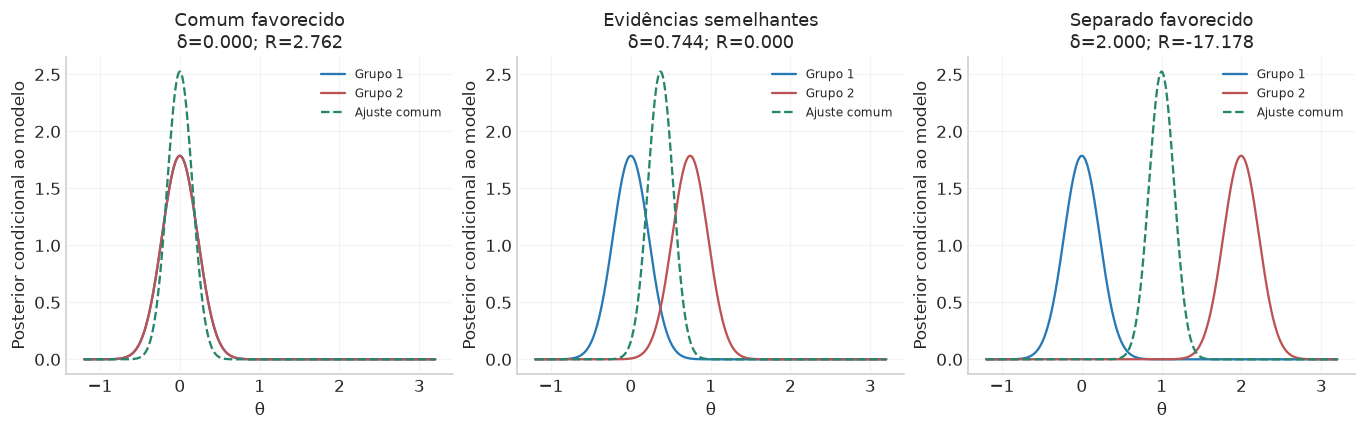

,Caso,δ,R = log B,B,log Z comum,log Z separado,Termo de volume,Termo de ajuste,Correção de prior,"P(comum), priors iguais"
0,Comum favorecido,0.0000,2.7622,15.8,-56.0644,-58.8266,2.7622,0.0000,0.0000,0.9406
1,Evidências semelhantes,0.7444,0.0000,1,-58.8377,-58.8377,2.7622,-2.7705,0.0083,0.5
2,Separado favorecido,2.0000,-17.1779,3.47e-08,-76.0844,-58.9065,2.7622,-20.0000,0.0599,3.465e-08


In [17]:
n1_R,n2_R,sigma_R=20,20,1.
V0_R=np.array([[25.]])
rng_R=np.random.default_rng(2802)
base1=rng_R.normal(size=n1_R);base1-=base1.mean()
base2=rng_R.normal(size=n2_R);base2-=base2.mean()
X_R=np.ones((n1_R+n2_R,1))
mask_R=np.arange(n1_R+n2_R)>=n1_R
def dados_deslocados(delta):
    return np.r_[base1,base2+delta]
def resultado_delta(delta):
    return robust_particao(dados_deslocados(delta),X_R,sigma_R,V0_R,mask_R)
delta_neutro=optimize.brentq(lambda d:resultado_delta(d)['R'],0,3)
casos_R=[('Comum favorecido',0.,VERDE),('Evidências semelhantes',delta_neutro,OURO),
         ('Separado favorecido',2.,VERMELHO)]
theta_R=np.linspace(-1.2,3.2,1000)
fig,ax=plt.subplots(1,3,figsize=(12.3,3.8),constrained_layout=True)
regs_R=[]
for a,(lab,d,cor) in zip(ax,casos_R):
    rr=resultado_delta(d)
    for tag,cor_p,ls in [('d1',AZUL,'-'),('d2',VERMELHO,'-'),('total',VERDE,'--')]:
        fit=rr[tag]
        a.plot(theta_R,stats.norm.pdf(theta_R,fit['media'][0],np.sqrt(fit['cov'][0,0])),
            color=cor_p,ls=ls,label={'d1':'Grupo 1','d2':'Grupo 2','total':'Ajuste comum'}[tag])
    a.set(xlabel='θ',ylabel='Posterior condicional ao modelo',title=lab+f"\nδ={d:.3f}; R={rr['R']:.3f}")
    a.legend(fontsize=8)
    regs_R.append({'Caso':lab,'δ':d,'R = log B':rr['R'],'B':f"{np.exp(rr['R']):.3g}",
        'log Z comum':rr['total']['logZ'],'log Z separado':rr['d1']['logZ']+rr['d2']['logZ'],
        'Termo de volume':rr['volume'],'Termo de ajuste':rr['ajuste'],
        'Correção de prior':rr['bias_prior'],'P(comum), priors iguais':f"{special.expit(rr['R']):.4g}"})
    verificar(f'Decomposição exata de R: {lab}',np.isclose(rr['R'],rr['volume']+rr['ajuste']+rr['bias_prior']))
figura(fig,'09_tres_casos_robustez_interna')
tabela(pd.DataFrame(regs_R),'tres_casos_R',casas=4)
verificar('Três regimes de robustez interna',resultado_delta(0)['R']>0 and abs(resultado_delta(delta_neutro)['R'])<1e-8 and resultado_delta(2)['R']<0)

### 10.1 O papel da prior e a distribuição nula de uma partição fixa

Separar melhora o ajuste e paga uma penalização por ampliar o espaço paramétrico. A prior controla parte desse preço: alargar muito a prior dos parâmetros extras pode favorecer o modelo comum. Isso é uma propriedade da comparação de modelos, não um motivo para ajustar priors até obter o resultado desejado.

Para **uma partição fixada antes de olhar os dados**, no modelo de média constante com erros conhecidos e hipótese comum verdadeira,
$$
\frac{\bar y_1-\bar y_2}{\sqrt{\sigma^2/n_1+\sigma^2/n_2}}\sim N(0,1),
\qquad \Delta\chi^2\sim\chi^2_1.
$$
No limite de prior larga,
$\mathcal R\simeq A_{\rm Occam}-\chi^2_1/2$.
Assim, $\mathcal R$ não segue, em geral, uma distribuição normal. Se procurarmos o menor $\mathcal R$ entre muitas partições, sua distribuição muda de novo. Calibrar uma partição isolada não calibra essa busca.

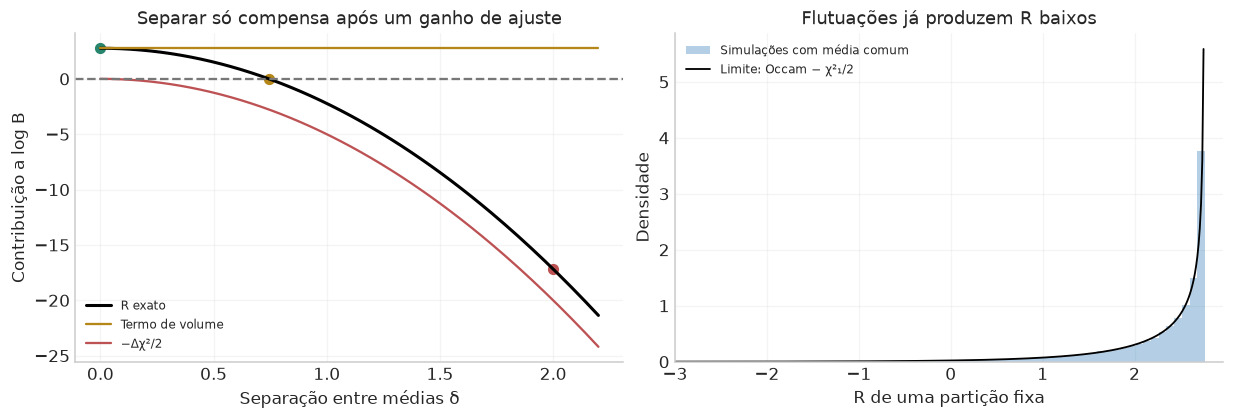

,Desvio prévio τ,R para os mesmos dados
0,1.0,-1.38650
1,3.0,-0.49352
2,10.0,0.68581
3,30.0,1.78224


In [18]:
ds=np.linspace(0,2.2,150);rrs=[resultado_delta(d) for d in ds]
fig,ax=plt.subplots(1,2,figsize=(11.1,3.7),constrained_layout=True)
ax[0].plot(ds,[r['R'] for r in rrs],color='black',lw=2,label='R exato')
ax[0].plot(ds,[r['volume'] for r in rrs],color=OURO,label='Termo de volume')
ax[0].plot(ds,[r['ajuste'] for r in rrs],color=VERMELHO,label='−Δχ²/2')
ax[0].axhline(0,color='#777777',ls='--')
for lab,d,cor in casos_R:ax[0].scatter([d],[resultado_delta(d)['R']],color=cor,s=40)
ax[0].set(xlabel='Separação entre médias δ',ylabel='Contribuição a log B',title='Separar só compensa após um ganho de ajuste');ax[0].legend(fontsize=8)
rng_null_R=np.random.default_rng(2803);n_rep_R=30000
means1=rng_null_R.normal(0,1/np.sqrt(n1_R),n_rep_R)
means2=rng_null_R.normal(0,1/np.sqrt(n2_R),n_rep_R)
l1,l2=n1_R,n2_R;p0=1/25;f1,f2,ft=l1+p0,l2+p0,l1+l2+p0
occ_exact=.5*np.log(f1*f2/(ft*p0))
R_null=occ_exact+.5*((l1*means1+l2*means2)**2/ft-(l1*means1)**2/f1-(l2*means2)**2/f2)
occ_broad=.5*np.log(l1*l2/((l1+l2)*p0))
r_curve=np.linspace(-4,occ_broad-.01,500)
ax[1].hist(R_null,bins=100,density=True,color=AZUL,alpha=.35,label='Simulações com média comum')
ax[1].plot(r_curve,2*stats.chi2.pdf(2*(occ_broad-r_curve),1),color='black',lw=1.2,label='Limite: Occam − χ²₁/2')
ax[1].set(xlim=(-3,occ_broad+.2),xlabel='R de uma partição fixa',ylabel='Densidade',title='Flutuações já produzem R baixos');ax[1].legend(fontsize=8)
figura(fig,'10_interna_fatores_nulo')
regs_prior=[]
for tau in [1.,3.,10.,30.]:
    r=robust_particao(dados_deslocados(delta_neutro),X_R,sigma_R,np.array([[tau*tau]]),mask_R)
    regs_prior.append({'Desvio prévio τ':tau,'R para os mesmos dados':r['R']})
tabela(pd.DataFrame(regs_prior),'interna_prior')

## 11. Slide 137: o limite de um único ponto

Considere $D_2=\{x_2\}$ e $D_1$ com $n$ medidas de uma mesma média, todas com erro $\sigma$. O ajuste separado ao ponto dá $\hat\chi^2_2=0$. Com $\bar x_1$ a média dos outros dados,
$$
\bar x_{\rm tot}=\frac{n\bar x_1+x_2}{n+1},
$$
$$
\Delta\chi^2=
\frac{n}{n+1}\frac{(x_2-\bar x_1)^2}{\sigma^2}
=\frac{(x_2-\bar x_1)^2}{\sigma^2+\sigma^2/n}.
$$
A última expressão mostra a incerteza da previsão do ponto a partir dos demais: erro do novo ponto **mais** erro da média estimada.

Se $n\gg1$ e desprezarmos o termo de volume e as correções da prior,
$$
\boxed{\mathcal R\simeq-\frac12
\frac{(x_2-\bar x_1)^2}{\sigma^2}.}
$$
Essa é a intuição do slide: um ponto muito distante do ajuste dos restantes reduz a robustez. Para $n$ pequeno precisamos do fator $n/(n+1)$; para interpretar o valor absoluto de $\mathcal R$, precisamos restaurar os termos de evidência.

O ajuste dos **restantes** é a referência que não é arrastada pelo ponto examinado. Usar o ajuste total pode mascarar um ponto influente, sobretudo em regressão com alavancagem.

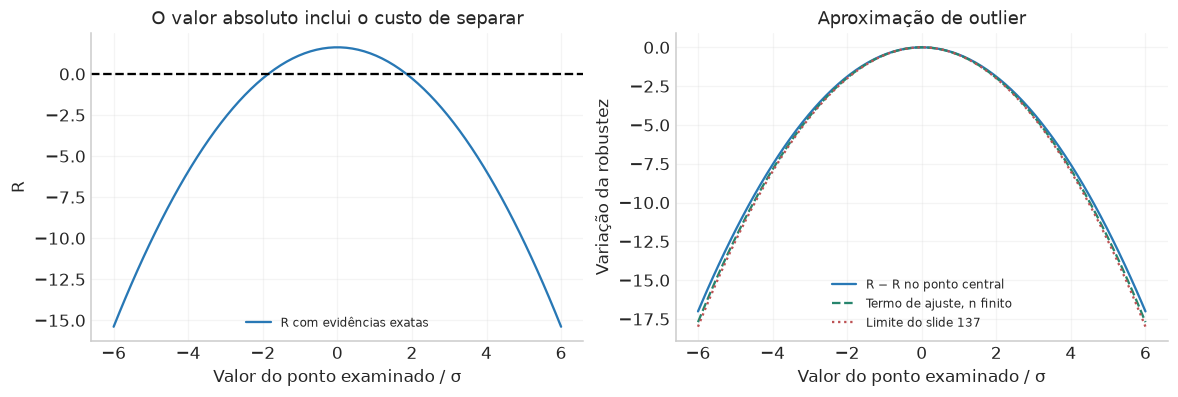

In [19]:
n_out=60;rng_out=np.random.default_rng(2804)
restantes=rng_out.normal(size=n_out);restantes-=restantes.mean()
X_out=np.ones((n_out+1,1));mask_out=np.arange(n_out+1)==n_out
ponto_out=np.linspace(-6,6,151)
R_out=np.array([robust_particao(np.r_[restantes,z],X_out,1.,V0_R,mask_out)['R'] for z in ponto_out])
R_centro=robust_particao(np.r_[restantes,0.],X_out,1.,V0_R,mask_out)['R']
delta_chi_out=n_out/(n_out+1)*ponto_out**2
fig,ax=plt.subplots(1,2,figsize=(10.6,3.5),constrained_layout=True)
ax[0].plot(ponto_out,R_out,color=AZUL,label='R com evidências exatas')
ax[0].axhline(0,color='black',ls='--')
ax[0].set(xlabel='Valor do ponto examinado / σ',ylabel='R',title='O valor absoluto inclui o custo de separar');ax[0].legend(fontsize=8)
ax[1].plot(ponto_out,R_out-R_centro,color=AZUL,label='R − R no ponto central')
ax[1].plot(ponto_out,-.5*delta_chi_out,'--',color=VERDE,label='Termo de ajuste, n finito')
ax[1].plot(ponto_out,-.5*ponto_out**2,':',color=VERMELHO,label='Limite do slide 137')
ax[1].set(xlabel='Valor do ponto examinado / σ',ylabel='Variação da robustez',title='Aproximação de outlier');ax[1].legend(fontsize=8)
figura(fig,'11_limite_outlier')
z_test=2.7
rt=robust_particao(np.r_[restantes,z_test],X_out,1.,V0_R,mask_out)
verificar('Identidade exata de Δχ² para um ponto',np.isclose(-2*rt['ajuste'],n_out/(n_out+1)*z_test**2))

## 12. Um catálogo com um problema de calibração escondido

Vamos construir um análogo simples dos slides 138–140. Vinte instrumentos medem uma resposta linear:
$$
y_i=a+b\,x_i+\varepsilon_i,\qquad
\varepsilon_i\sim N(0,\sigma^2).
$$
$x$ é uma entrada adimensional, $y$ é uma tensão em volts, $a$ é um offset e $b$ é a resposta por unidade de $x$. Cada instrumento mede 12 posições entre $-1$ e 1; os erros conhecidos são $\sigma=0{,}3$ V, independentes. O gerador usa $(a,b)=(1,0{,}6)$.

Depois acrescentamos um offset de $0{,}3$ V aos 12 dados do instrumento 8. O deslocamento de **cada ponto** é de apenas um desvio padrão do ruído. A média de um grupo, porém, é medida com erro da ordem de $\sigma/\sqrt{12}$, e um deslocamento coerente pode ser detectável coletivamente.

A prior dos parâmetros é $N(0,\operatorname{diag}(3^2,3^2))$, nas unidades correspondentes. O rótulo verdadeiro da contaminação será usado para **validar e colorir** a simulação. A procura usará os dados, o modelo, as incertezas e os identificadores dos instrumentos; não receberá o rótulo de qual instrumento contaminamos.

O $\chi^2$ global testa o ajuste total e pode diluir um problema localizado. A robustez pergunta se uma partição favorece parâmetros diferentes. Vamos registrar ambos. Em sentido estrito, heterocedasticidade é mudança de variância; este exemplo tem **médias heterogêneas com variâncias iguais**, mostrando que a pergunta de robustez é mais ampla que um teste exclusivo de variâncias.

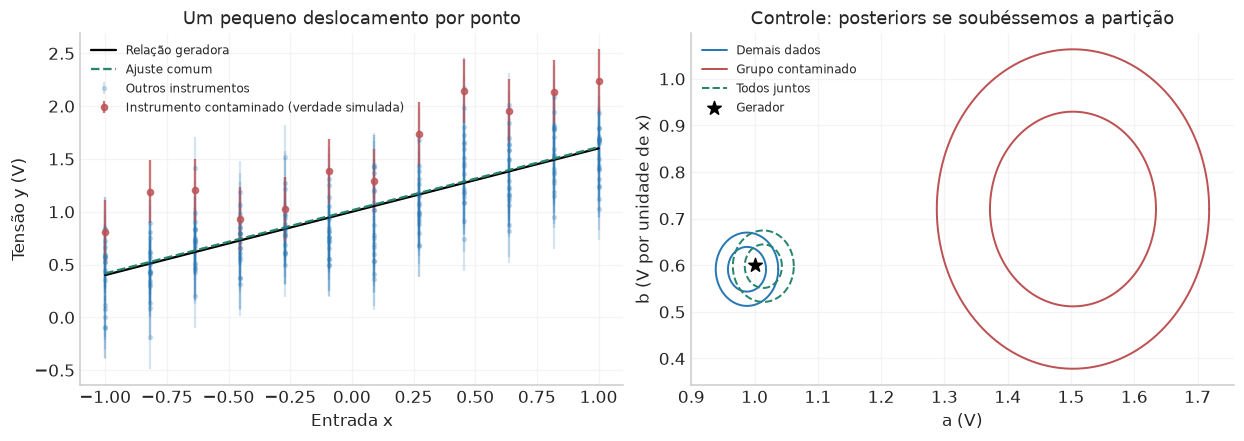

,N,χ² mínimo global,Graus de liberdade,p global de χ²,R da partição verdadeira (controle)
0,240,253.94744,238,0.22795,-10.58495


A partição verdadeira acima serve de controle; a busca a seguir não usa esse rótulo.


In [20]:
G_cat,m_cat=20,12;N_cat=G_cat*m_cat
instrumento=np.repeat(np.arange(1,G_cat+1),m_cat)
x_cat=np.tile(np.linspace(-1,1,m_cat),G_cat)
X_cat=np.column_stack([np.ones(N_cat),x_cat])
theta_verdade=np.array([1.,.6]);sig_cat=.3
V0_cat=np.diag([9.,9.])
rng_cat=np.random.default_rng(261110)
y_sem_bias=X_cat@theta_verdade+rng_cat.normal(0,sig_cat,N_cat)
verdade_ruim=instrumento==8
y_cat=y_sem_bias+.3*verdade_ruim
fit_cat=ajustar_linear(y_cat,X_cat,sig_cat,V0_cat)
controle_part=robust_particao(y_cat,X_cat,sig_cat,V0_cat,verdade_ruim)
p_chi_global=stats.chi2.sf(fit_cat['chi2'],N_cat-fit_cat['rank'])

fig,ax=plt.subplots(1,2,figsize=(11.2,3.9),constrained_layout=True)
ax[0].errorbar(x_cat[~verdade_ruim],y_cat[~verdade_ruim],yerr=sig_cat,
    fmt='o',ms=2.5,alpha=.2,color=AZUL,label='Outros instrumentos')
ax[0].errorbar(x_cat[verdade_ruim],y_cat[verdade_ruim],yerr=sig_cat,
    fmt='o',ms=4,alpha=.8,color=VERMELHO,label='Instrumento contaminado (verdade simulada)')
xf=np.linspace(-1,1,200)
ax[0].plot(xf,theta_verdade[0]+theta_verdade[1]*xf,color='black',label='Relação geradora')
ax[0].plot(xf,fit_cat['media'][0]+fit_cat['media'][1]*xf,'--',color=VERDE,label='Ajuste comum')
ax[0].set(xlabel='Entrada x',ylabel='Tensão y (V)',title='Um pequeno deslocamento por ponto');ax[0].legend(fontsize=8)
for tag,cor,lab in [('d1',AZUL,'Demais dados'),('d2',VERMELHO,'Grupo contaminado'),('total',VERDE,'Todos juntos')]:
    fit=controle_part[tag]
    elipse(ax[1],fit['media'],fit['cov'],cor,label=lab,ls='--' if tag=='total' else '-')
ax[1].scatter(*theta_verdade,marker='*',s=85,color='black',label='Gerador')
ax[1].set(xlabel='a (V)',ylabel='b (V por unidade de x)',title='Controle: posteriors se soubéssemos a partição')
ax[1].legend(fontsize=8)
figura(fig,'12_catalogo_contaminado')
tabela(pd.DataFrame([{'N':N_cat,'χ² mínimo global':fit_cat['chi2'],'Graus de liberdade':N_cat-2,
    'p global de χ²':p_chi_global,'R da partição verdadeira (controle)':controle_part['R']}]),'catalogo_controle')
print('A partição verdadeira acima serve de controle; a busca a seguir não usa esse rótulo.')

## 13. Como procurar o subconjunto?

Com $N$ pontos há $2^N$ subconjuntos. Excluindo vazio e conjunto inteiro e identificando partições que só trocam os nomes dos lados, restam
$$
N_{\rm partições}=2^{N-1}-1.
$$
Essa identificação pressupõe que os dois lados têm papéis e priors intercambiáveis, como em nosso teste inicial. Se as hipóteses dos lados forem distintas, suas atribuições também importam.

A busca exaustiva cresce exponencialmente. O limite prático não é um número universal de pontos: depende do custo de cada evidência e da estrutura do modelo. As soluções dos slides 139–141 são procurar apenas algumas partições e usar agrupamentos que aproveitem informação física.

| Estratégia | Procedimento | O que pode deixar de encontrar |
|---|---|---|
| Partições aleatórias por ponto | Sortear tamanho e membros do subconjunto, calcular $\mathcal R$, guardar os menores | Um grupo contaminado específico pode quase nunca ser sorteado inteiro |
| Agrupamento prévio | Definir grupos por instrumento, época, região, seleção ou faixa observacional | Contaminação que não respeita esses grupos |
| Refinamento em níveis | Examinar grupos, subdividir candidatos e comparar com seus complementos | Uma busca gulosa pode escolher um ramo inadequado |
| Modelo explícito de calibração | Incluir offsets/efeitos físicos e comparar evidências | Sistemáticas fora da família de modelos considerada |

O agrupamento deve ser registrado e fundamentado pelo processo de medição. Grupos definidos depois de olhar resíduos também podem ser explorados, mas essa seleção passa a fazer parte do algoritmo a calibrar.

### 13.1 Tornar a procura barata sem alterar a estatística

Neste catálogo os $\sigma$ são iguais e a prior é centrada em zero. Para uma máscara $M_j$ que seleciona $D_2$, pré-calculamos
$$
L_j=\sum_{i\in M_j}\frac{X_i^TX_i}{\sigma^2},\quad
F_{j,2}=L_j+P,\quad F_{j,1}=L_{\rm tot}-L_j+P.
$$
Para cada catálogo, só mudam
$$
g_{\rm tot}=\sum_iX_i^Ty_i/\sigma^2,\quad
g_{j,2}=\sum_{i\in M_j}X_i^Ty_i/\sigma^2,\quad
g_{j,1}=g_{\rm tot}-g_{j,2}.
$$
Os termos $\sum y_i^2/\sigma^2$ e as normalizações dos erros cancelam em $\mathcal R$:
$$
\begin{aligned}
\mathcal R_j={}&
\frac12\ln\frac{\det F_{j,1}\det F_{j,2}}{\det F_{\rm tot}\det P}\\
&+\frac12\left[
g_{\rm tot}^TF_{\rm tot}^{-1}g_{\rm tot}
-g_{j,1}^TF_{j,1}^{-1}g_{j,1}
-g_{j,2}^TF_{j,2}^{-1}g_{j,2}\right].
\end{aligned}
$$
Essa é a evidência gaussiana **exata** reorganizada em estatísticas suficientes. Vamos comparar a implementação em lote com a função de ajuste anterior antes de usá-la nos mocks.

In [21]:
def preparar_busca(X,sigma,V0,mascaras):
    X=np.asarray(X,float);mascaras=np.asarray(mascaras,bool)
    N,k=X.shape
    tamanhos=mascaras.sum(axis=1)
    if np.any((tamanhos==0)|(tamanhos==N)):raise ValueError('Há uma partição vazia.')
    P0=np.linalg.solve(V0,np.eye(k))
    Ltot=X.T@X/sigma**2
    L2=np.einsum('bn,ni,nj->bij',mascaras.astype(float),X,X,optimize=True)/sigma**2
    Ft=Ltot+P0;F2=L2+P0;F1=Ltot[None]-L2+P0
    logF1=np.linalg.slogdet(F1)[1];logF2=np.linalg.slogdet(F2)[1]
    identidade=np.broadcast_to(np.eye(k),F1.shape)
    return {'X':X,'sigma':float(sigma),'mascaras':mascaras.astype(float),
        'Vt':cov_de_precisao(Ft),'V1':np.linalg.solve(F1,identidade),
        'V2':np.linalg.solve(F2,identidade),
        'occam':.5*(logF1+logF2-logdet(Ft)-logdet(P0))}

def avaliar_busca(y,preparo):
    y=np.asarray(y,float);unico=y.ndim==1;Y=np.atleast_2d(y)
    X=preparo['X'];s=preparo['sigma']
    gt=Y@X/s**2
    # Eixos: r = catálogo, b = partição, k = parâmetro.
    g2=np.einsum('bn,rnk->rbk',preparo['mascaras'],
        Y[:,:,None]*(X/s**2)[None,:,:],optimize=True)
    g1=gt[:,None,:]-g2
    qt=np.einsum('ri,ij,rj->r',gt,preparo['Vt'],gt)
    q1=np.einsum('rbi,bij,rbj->rb',g1,preparo['V1'],g1)
    q2=np.einsum('rbi,bij,rbj->rb',g2,preparo['V2'],g2)
    R=preparo['occam'][None,:]+.5*(qt[:,None]-q1-q2)
    return R[0] if unico else R

rng_busca=np.random.default_rng(2810)
n_por_pontos=900
mascaras_pontos=np.zeros((n_por_pontos,N_cat),bool)
for j in range(n_por_pontos):
    tam=int(rng_busca.choice([12,24,48]))
    mascaras_pontos[j,rng_busca.choice(N_cat,tam,replace=False)]=True

mascaras_instrumentos=instrumento[None,:]==np.arange(1,G_cat+1)[:,None]
pares=list(combinations(range(G_cat),2))
mascaras_pares=np.array([mascaras_instrumentos[i]|mascaras_instrumentos[j] for i,j in pares])
mascaras_grupos_rand=[]
for j in range(300):
    membros=rng_busca.choice(np.arange(1,G_cat+1),int(rng_busca.integers(3,7)),replace=False)
    mascaras_grupos_rand.append(np.isin(instrumento,membros))
# Metades intercaladas de cada instrumento mantêm cobertura aproximadamente igual em x.
mascaras_metades=[]
for g in range(1,G_cat+1):
    ids=np.flatnonzero(instrumento==g)
    for lado in [0,1]:
        mask=np.zeros(N_cat,bool);mask[ids[lado::2]]=True;mascaras_metades.append(mask)
mascaras_metades=np.array(mascaras_metades)
mascaras_bins=np.vstack([mascaras_instrumentos,mascaras_pares,mascaras_grupos_rand,mascaras_metades])
mascaras_todas=np.vstack([mascaras_pontos,mascaras_bins])
preparo_cat=preparar_busca(X_cat,sig_cat,V0_cat,mascaras_todas)
R_cat=avaliar_busca(y_cat,preparo_cat)
R_pontos=R_cat[:n_por_pontos];R_bins=R_cat[n_por_pontos:]
R_instrumentos=R_bins[:G_cat]
for j in [0,n_por_pontos,n_por_pontos+7,len(mascaras_todas)-1]:
    direto=robust_particao(y_cat,X_cat,sig_cat,V0_cat,mascaras_todas[j])['R']
    verificar(f'Busca em lote coincide com evidência direta: partição {j}',np.isclose(R_cat[j],direto,atol=1e-8))
melhor_idx=int(np.argmin(R_cat));mascara_candidata=mascaras_todas[melhor_idx]
regs_busca=[]
for lab,Rvals,masks in [('Pontos aleatórios',R_pontos,mascaras_pontos),('Grupos e refinamentos',R_bins,mascaras_bins)]:
    j=np.argmin(Rvals);sel=masks[j]
    regs_busca.append({'Busca':lab,'Tentativas':len(Rvals),'Menor R':Rvals[j],
        'Tamanho do candidato':sel.sum(),
        'Contaminados no candidato (validação)':np.sum(sel&verdade_ruim)})
tabela(pd.DataFrame(regs_busca),'resultados_busca')

,Busca,Tentativas,Menor R,Tamanho do candidato,Contaminados no candidato (validação)
0,Pontos aleatórios,900,-1.20024,24,3
1,Grupos e refinamentos,550,-10.58495,12,12


### 13.2 Localizar candidatos sem confundir um ranking com uma probabilidade

Para resumir as partições por grupos, selecionaremos os 2% com menor $\mathcal R$ e calcularemos a frequência com que cada ponto aparece no lado menor. Essa frequência é uma **heurística de associação aos candidatos**, não $P(\text{ponto contaminado}\mid D)$.

Os tamanhos e priors afetam $\mathcal R$, e as partições são correlacionadas. Uma probabilidade de contaminação exige um modelo probabilístico para essa contaminação; construiremos um exemplo explícito na seção 15.

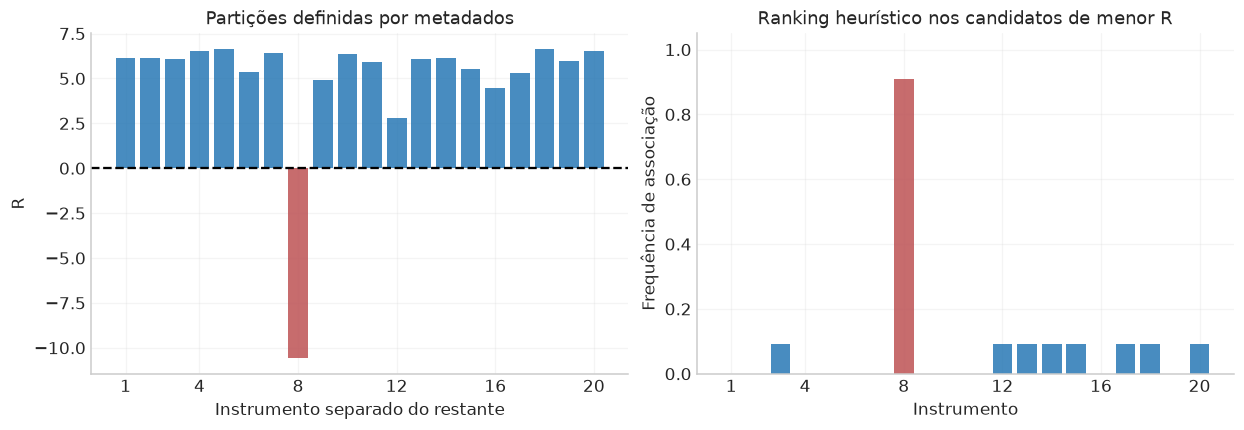

,Instrumento,R ao separar o instrumento,Score heurístico
7,8,-10.58495,0.90909
11,12,2.79224,0.09091
15,16,4.46596,0.00000
8,9,4.91041,0.00000
16,17,5.30469,0.09091
5,6,5.34445,0.00000


In [22]:
limiar_candidatos=np.quantile(R_bins,.02)
candidatos_baixos=R_bins<=limiar_candidatos
score_associacao=mascaras_bins[candidatos_baixos].mean(axis=0)
score_por_inst=np.array([score_associacao[instrumento==g].mean() for g in range(1,G_cat+1)])
fig,ax=plt.subplots(1,2,figsize=(11.2,3.8),constrained_layout=True)
cores_inst=[VERMELHO if g==8 else AZUL for g in range(1,G_cat+1)]
ax[0].bar(np.arange(1,G_cat+1),R_instrumentos,color=cores_inst,alpha=.85)
ax[0].axhline(0,color='black',ls='--')
ax[0].set(xlabel='Instrumento separado do restante',ylabel='R',title='Partições definidas por metadados')
ax[1].bar(np.arange(1,G_cat+1),score_por_inst,color=cores_inst,alpha=.85)
ax[1].set(xlabel='Instrumento',ylabel='Frequência de associação',ylim=(0,1.05),
    title='Ranking heurístico nos candidatos de menor R')
for a in ax:a.set_xticks([1,4,8,12,16,20])
figura(fig,'13_localizacao_por_grupos')
tabela(pd.DataFrame({'Instrumento':np.arange(1,G_cat+1),'R ao separar o instrumento':R_instrumentos,
    'Score heurístico':score_por_inst}).sort_values('R ao separar o instrumento').head(6),'instrumentos_candidatos')

### 13.3 Refinamento em níveis e custo de busca

Para tornar concreta a sugestão dos slides, começaremos com pares de instrumentos vizinhos na sequência de aquisição. Escolheremos o par de menor $\mathcal R$, compararemos cada instrumento desse par com o restante e depois suas metades intercaladas. Em cada etapa guardamos o melhor candidato já visto, inclusive o pai: subdividir um grupo pode reduzir a informação a ponto de piorar a capacidade de reconhecer um desvio coerente.

É uma estratégia gulosa, sem garantia de mínimo global. Se o primeiro ramo escolhido estiver errado, pode perder uma contaminação em outro ramo. Por isso a busca mais ampla por grupos continua sendo uma comparação útil.

Todas as partições que essa pequena árvore pode visitar já estão incluídas na família pré-definida acima: pares, instrumentos e metades. Nos mocks avaliaremos o mínimo da família completa. Se uma adaptação criar novas partições fora dela, será necessário repetir também essa adaptação em cada mock.

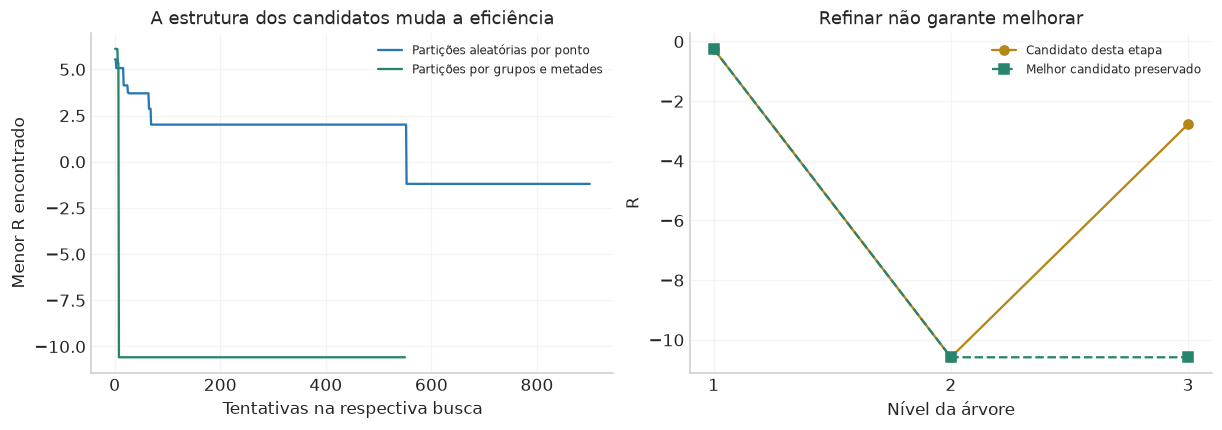

,Etapa,Candidatos avaliados,Tamanho escolhido,R da etapa,Melhor R acumulado
0,Pares de instrumentos,10,24,-0.24423,-0.24423
1,Instrumentos do par escolhido,2,12,-10.58495,-10.58495
2,Metades do instrumento escolhido,2,6,-2.77277,-10.58495


,N,Partições não rotuladas
0,12,2.047e+03
1,20,5.243e+05
2,40,5.498e+11
3,240,8.834e+71
4,580,1.979e+174


In [23]:
coarse_grupos=[(g,g+1) for g in range(1,G_cat+1,2)]
mascaras_coarse=np.array([np.isin(instrumento,par) for par in coarse_grupos])
R_coarse=avaliar_busca(y_cat,preparar_busca(X_cat,sig_cat,V0_cat,mascaras_coarse))
j_coarse=int(np.argmin(R_coarse));par_ativo=coarse_grupos[j_coarse]
inst_ativo=min(par_ativo,key=lambda g:R_instrumentos[g-1])
R_filho=R_instrumentos[inst_ativo-1]
R_metades=R_bins[-2*G_cat:][2*(inst_ativo-1):2*inst_ativo]
j_metade=int(np.argmin(R_metades))
traj_busca=pd.DataFrame([
    {'Etapa':'Pares de instrumentos','Candidatos avaliados':len(R_coarse),'Tamanho escolhido':2*m_cat,'R da etapa':R_coarse[j_coarse]},
    {'Etapa':'Instrumentos do par escolhido','Candidatos avaliados':2,'Tamanho escolhido':m_cat,'R da etapa':R_filho},
    {'Etapa':'Metades do instrumento escolhido','Candidatos avaliados':2,'Tamanho escolhido':m_cat//2,'R da etapa':R_metades[j_metade]}])
traj_busca['Melhor R acumulado']=np.minimum.accumulate(traj_busca['R da etapa'])
fig,ax=plt.subplots(1,2,figsize=(11,3.8),constrained_layout=True)
ax[0].plot(np.arange(1,len(R_pontos)+1),np.minimum.accumulate(R_pontos),color=AZUL,label='Partições aleatórias por ponto')
ax[0].plot(np.arange(1,len(R_bins)+1),np.minimum.accumulate(R_bins),color=VERDE,label='Partições por grupos e metades')
ax[0].set(xlabel='Tentativas na respectiva busca',ylabel='Menor R encontrado',title='A estrutura dos candidatos muda a eficiência');ax[0].legend(fontsize=8)
ax[1].plot(np.arange(1,4),traj_busca['R da etapa'],'o-',color=OURO,label='Candidato desta etapa')
ax[1].plot(np.arange(1,4),traj_busca['Melhor R acumulado'],'s--',color=VERDE,label='Melhor candidato preservado')
ax[1].set(xticks=[1,2,3],xlabel='Nível da árvore',ylabel='R',title='Refinar não garante melhorar');ax[1].legend(fontsize=8)
figura(fig,'14_busca_e_refinamento')
tabela(traj_busca,'refinamento_hierarquico')
tabela(pd.DataFrame({'N':[12,20,40,240,580],
    'Partições não rotuladas':[f'{2**(n-1)-1:.3e}' for n in [12,20,40,240,580]]}),'numero_particoes')

## 14. Slide 141: como saber se o mínimo encontrado é anormal?

Mesmo um catálogo perfeitamente descrito pelo modelo produz subdivisões com médias diferentes por acaso. Examinar muitas partições aumenta a chance de encontrar alguma com $\mathcal R$ baixo. O resultado da seção anterior precisa de uma **distribuição nula da busca inteira**.

Nosso procedimento será:

1. Manter posições $x$, identificadores, erros, priors, máscaras candidatas e critérios de seleção.
2. Gerar muitos catálogos sem o offset, com os parâmetros do modelo gerador.
3. Refazer todos os ajustes e a procura do menor $\mathcal R$ em cada catálogo.
4. Comparar o mínimo observado com essa distribuição de mínimos.

Nesta simulação conhecemos os parâmetros geradores. Em dados reais, uma calibração paramétrica pode usar parâmetros ajustados sob o modelo nulo e deve avaliar a sensibilidade a essa escolha, às incertezas e às seleções. Sortear parâmetros de uma posterior preditiva produz outro tipo de calibração e precisa ser identificado como tal.

Defina $T(D)=\min_j\mathcal R_j(D)$. Com $M$ mocks,
$$
\hat p_{\rm MC}=
\frac{1+\#\{T(D^{(s)})\leq T(D_{\rm obs})\}}{M+1}.
$$
A correção de contagem evita relatar $p=0$ quando nenhum mock foi tão extremo. Ela não cria resolução infinita: com 400 mocks, a escala mínima resolvida é da ordem de $1/400$. Para uma cauda menor seriam necessários mais mocks ou outro cálculo de cauda justificado.

Também desenharemos, como nos slides, a distribuição dos valores de $\mathcal R$ ao longo das partições. As bandas de mocks serão intervalos empíricos **ponto a ponto em cada bin**. As partições dentro de um catálogo não são amostras independentes; essas bandas não são uma significância global. O teste global apresentado é o do mínimo da busca.

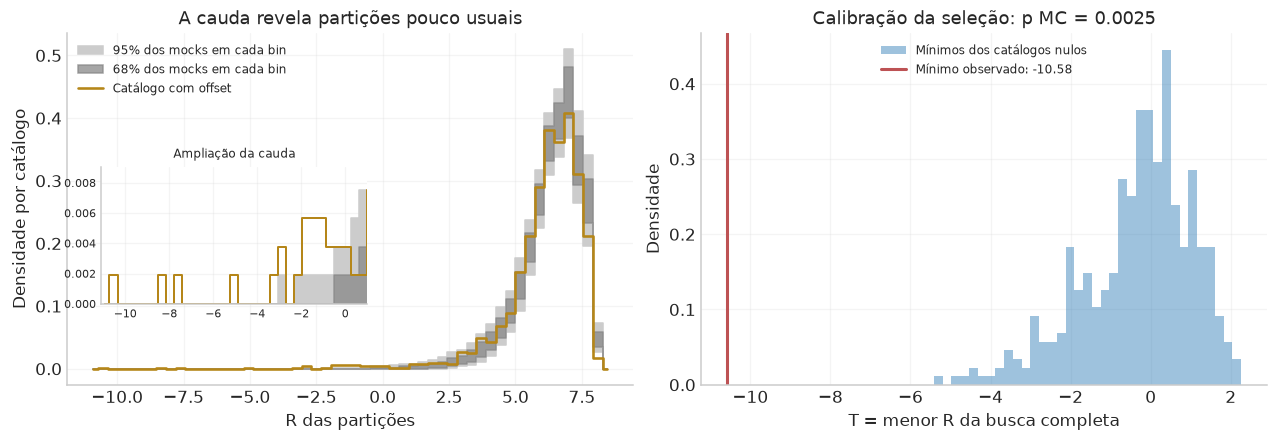

,Mocks,Partições por catálogo,T observado,Mocks tão ou mais extremos,p MC da busca,p do χ² global
0,400,1450,-10.58495,0,0.00249,0.22795


In [24]:
N_MOCKS=400
rng_mocks=np.random.default_rng(2811)
Y_mocks=X_cat@theta_verdade+rng_mocks.normal(0,sig_cat,(N_MOCKS,N_cat))
R_mocks=avaliar_busca(Y_mocks,preparo_cat)
T_mocks=R_mocks.min(axis=1);T_observado=R_cat.min()
n_mais_extremos=int(np.sum(T_mocks<=T_observado))
p_MC=(1+n_mais_extremos)/(N_MOCKS+1)
lim_inf=min(T_observado,R_mocks.min())-.5
lim_sup=max(R_cat.max(),R_mocks.max())+.5
bins_R=np.linspace(lim_inf,lim_sup,55);centros_R=(bins_R[:-1]+bins_R[1:])/2
hists_mock=np.array([np.histogram(row,bins=bins_R,density=True)[0] for row in R_mocks])
faixas=np.quantile(hists_mock,[.025,.16,.5,.84,.975],axis=0)
hist_obs=np.histogram(R_cat,bins=bins_R,density=True)[0]
fig,ax=plt.subplots(1,2,figsize=(11.5,3.9),constrained_layout=True)
ax[0].fill_between(centros_R,faixas[0],faixas[4],step='mid',color='#cccccc',label='95% dos mocks em cada bin')
ax[0].fill_between(centros_R,faixas[1],faixas[3],step='mid',color='#888888',alpha=.75,label='68% dos mocks em cada bin')
ax[0].step(centros_R,hist_obs,where='mid',color=OURO,lw=1.7,label='Catálogo com offset')
ax[0].set(xlabel='R das partições',ylabel='Densidade por catálogo',title='A cauda revela partições pouco usuais');ax[0].legend(fontsize=8)
zoom_cauda=ax[0].inset_axes([.06,.23,.47,.39])
zoom_cauda.fill_between(centros_R,faixas[0],faixas[4],step='mid',color='#cccccc')
zoom_cauda.fill_between(centros_R,faixas[1],faixas[3],step='mid',color='#888888',alpha=.75)
zoom_cauda.step(centros_R,hist_obs,where='mid',color=OURO,lw=1.3)
tail=centros_R<1.
ymax_tail=max(np.max(faixas[4,tail]),np.max(hist_obs[tail]))
zoom_cauda.set(xlim=(lim_inf,1),ylim=(0,1.2*ymax_tail),title='Ampliação da cauda')
zoom_cauda.title.set_fontsize(8);zoom_cauda.tick_params(labelsize=7)
ax[1].hist(T_mocks,bins=35,density=True,color=AZUL,alpha=.45,label='Mínimos dos catálogos nulos')
ax[1].axvline(T_observado,color=VERMELHO,lw=2,label=f'Mínimo observado: {T_observado:.2f}')
ax[1].set(xlabel='T = menor R da busca completa',ylabel='Densidade',title=f'Calibração da seleção: p MC = {p_MC:.4f}')
ax[1].legend(fontsize=8)
figura(fig,'15_mocks_distribuicao_robustez')
tabela(pd.DataFrame([{'Mocks':N_MOCKS,'Partições por catálogo':len(mascaras_todas),
    'T observado':T_observado,'Mocks tão ou mais extremos':n_mais_extremos,'p MC da busca':p_MC,
    'p do χ² global':p_chi_global}]),'calibracao_busca')
verificar('Número de mínimos coincide com catálogos nulos',len(T_mocks)==N_MOCKS)

Essa calibração trata o **algoritmo de procura especificado**. Mudar tamanhos, agrupamentos ou critérios depois de ver o resultado amplia a família pesquisada. Se isso fizer parte da análise, precisa fazer parte também da calibração.

Um diagnóstico global menos expressivo pode coexistir com uma partição muito incomum. São sensibilidades diferentes: o $\chi^2$ agrega o desajuste total, enquanto a busca procura uma estrutura coerente entre subconjuntos. Os números da tabela registram o que ocorreu nesta realização, sem substituir uma distribuição nula por um limiar universal de $\mathcal R$.

## 15. Depois de localizar um candidato: modelar a calibração

Descartar automaticamente os dados de menor $\mathcal R$ pode produzir uma amostra artificialmente concordante. Vamos, em vez disso, testar uma explicação que usa **todos os dados**:
$$
H_{\rm off,g}:\quad
y_i=a+b\,x_i+\Delta\,{\bf1}(\text{instrumento}_i=g)+\varepsilon_i.
$$
O novo parâmetro $\Delta$ é um offset de calibração com prior própria
$\Delta\sim N(0,0{,}5^2\ \mathrm{V}^2)$.
Mantemos a prior de $(a,b)$, escolhemos previamente
$P(g\mid H_{\rm off})=1/20$ e integramos também **qual instrumento** pode ter o offset:
$$
Z_{\rm off}=\frac1{20}\sum_{g=1}^{20}Z_{\rm off,g}.
$$
O fator $1/20$ é importante. Escolher apenas a maior evidência depois da busca não é a evidência dessa hipótese com índice de instrumento desconhecido.

Para manter a orientação dos quocientes, definimos
$$
\mathcal R_{\rm calib}=\ln Z_c-\ln Z_{\rm off}.
$$
Valores negativos favorecem a alternativa de calibração. Com probabilidades prévias iguais entre $H_c$ e $H_{\rm off}$,
$$
P(H_{\rm off}\mid D)=\frac{Z_{\rm off}}{Z_c+Z_{\rm off}},
$$
$$
P(g\mid H_{\rm off},D)=\frac{Z_{\rm off,g}}{\sum_hZ_{\rm off,h}}.
$$
Agora há probabilidades interpretáveis, **condicionadas a uma família explícita de modelos**, em vez de chamar o score heurístico de probabilidade.

A posterior de $(a,b)$ sob a alternativa é uma mistura dos posteriors de cada $g$. Se $w_g=P(g\mid H_{\rm off},D)$, sua média é
$\bar m=\sum_gw_gm_g$ e sua covariância é
$$
\bar V=\sum_gw_g\left[V_g+(m_g-\bar m)(m_g-\bar m)^T\right].
$$
O segundo termo inclui a incerteza sobre o instrumento. Ignorá-lo e manter apenas o ajuste escolhido mais favorável subestima a incerteza quando há ambiguidade.

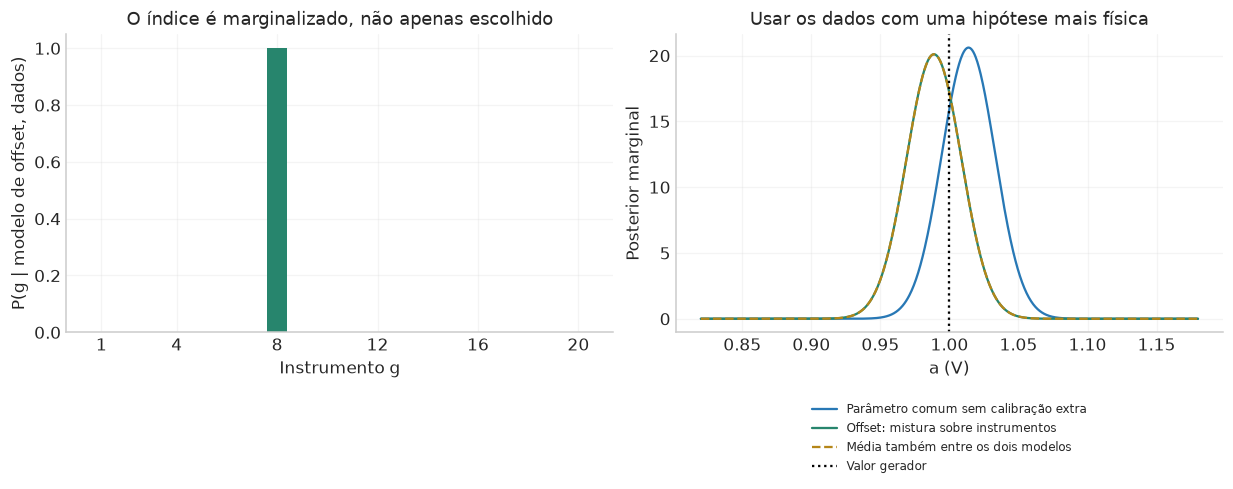

,Parâmetro,Gerador,"Média, modelo comum","Desvio, modelo comum","Média, alternativa offset","Desvio, alternativa offset",Média entre modelos,Desvio entre modelos
0,a,1.0,1.01383,0.01936,0.98880,0.01985,0.98880,0.01985
1,b,0.6,0.59798,0.03085,0.59798,0.03085,0.59798,0.03085


,R calibração (comum/offset),"P(offset|D), priors iguais",Instrumento de maior peso,"P(g|offset,D)",Offset médio nesse instrumento,Desvio do offset
0,-11.63165,0.99999,8,1.0,0.50057,0.08748


In [25]:
fits_offset=[]
V0_offset=np.diag([9.,9.,.5**2])
for g in range(1,G_cat+1):
    Xg=np.column_stack([X_cat,(instrumento==g).astype(float)])
    fits_offset.append(ajustar_linear(y_cat,Xg,sig_cat,V0_offset))
logZ_grupos=np.array([f['logZ'] for f in fits_offset])
logZ_offset=special.logsumexp(logZ_grupos)-np.log(G_cat)
pesos_offset=special.softmax(logZ_grupos)
R_calibracao=fit_cat['logZ']-logZ_offset
prob_offset=special.expit(-R_calibracao)
means_offset=np.array([f['media'][:2] for f in fits_offset])
covs_offset=np.array([f['cov'][:2,:2] for f in fits_offset])
media_offset=np.einsum('g,gk->k',pesos_offset,means_offset)
desvios_offset=means_offset-media_offset
cov_offset=np.einsum('g,gij->ij',pesos_offset,
    covs_offset+np.einsum('gi,gj->gij',desvios_offset,desvios_offset))
media_modelos=(1-prob_offset)*fit_cat['media']+prob_offset*media_offset
cov_modelos=((1-prob_offset)*(fit_cat['cov']+np.outer(fit_cat['media']-media_modelos,fit_cat['media']-media_modelos))+
    prob_offset*(cov_offset+np.outer(media_offset-media_modelos,media_offset-media_modelos)))

fig,ax=plt.subplots(1,2,figsize=(11.1,4.3),constrained_layout=True)
ax[0].bar(np.arange(1,G_cat+1),pesos_offset,color=VERDE)
ax[0].set(xlabel='Instrumento g',ylabel='P(g | modelo de offset, dados)',title='O índice é marginalizado, não apenas escolhido')
ax[0].set_xticks([1,4,8,12,16,20])
aa=np.linspace(theta_verdade[0]-.18,theta_verdade[0]+.18,900)
pdf_com=stats.norm.pdf(aa,fit_cat['media'][0],np.sqrt(fit_cat['cov'][0,0]))
pdf_off=sum(w*stats.norm.pdf(aa,f['media'][0],np.sqrt(f['cov'][0,0])) for w,f in zip(pesos_offset,fits_offset))
pdf_avg=(1-prob_offset)*pdf_com+prob_offset*pdf_off
ax[1].plot(aa,pdf_com,color=AZUL,label='Parâmetro comum sem calibração extra')
ax[1].plot(aa,pdf_off,color=VERDE,label='Offset: mistura sobre instrumentos')
ax[1].plot(aa,pdf_avg,'--',color=OURO,label='Média também entre os dois modelos')
ax[1].axvline(theta_verdade[0],color='black',ls=':',label='Valor gerador')
ax[1].set(xlabel='a (V)',ylabel='Posterior marginal',title='Usar os dados com uma hipótese mais física')
ax[1].legend(fontsize=8,loc='upper center',bbox_to_anchor=(.5,-.2))
figura(fig,'16_modelo_calibracao')
tabela(pd.DataFrame({'Parâmetro':['a','b'],'Gerador':theta_verdade,
    'Média, modelo comum':fit_cat['media'],'Desvio, modelo comum':np.sqrt(np.diag(fit_cat['cov'])),
    'Média, alternativa offset':media_offset,'Desvio, alternativa offset':np.sqrt(np.diag(cov_offset)),
    'Média entre modelos':media_modelos,'Desvio entre modelos':np.sqrt(np.diag(cov_modelos))}),'parametros_calibracao')
g_mais=int(np.argmax(pesos_offset))+1
tabela(pd.DataFrame([{'R calibração (comum/offset)':R_calibracao,'P(offset|D), priors iguais':prob_offset,
    'Instrumento de maior peso':g_mais,'P(g|offset,D)':pesos_offset[g_mais-1],
    'Offset médio nesse instrumento':fits_offset[g_mais-1]['media'][2],
    'Desvio do offset':np.sqrt(fits_offset[g_mais-1]['cov'][2,2])}]),'evidencia_calibracao')
verificar('Probabilidades de instrumento normalizadas',np.isclose(pesos_offset.sum(),1))
verificar('Mistura de covariâncias é positiva definida',np.linalg.eigvalsh(cov_offset).min()>0)

### 15.1 O que seria feito em uma análise real?

Depois do diagnóstico, procuramos relações com época, instrumento, seleção, calibração, condições de observação e covariâncias compartilhadas. Conferimos os dados originais e, se possível, usamos uma amostra independente para validar a explicação.

O modelo de offset acima é uma possibilidade, não uma explicação universal. Outros casos pedem dispersões diferentes entre grupos, um modelo de mistura de populações, uma likelihood de caudas mais pesadas ou uma alteração da previsão física. Se a seleção do candidato ou a família de modelos foi construída a partir dos resultados, essa etapa precisa ser incorporada à interpretação e à calibração, ou validada com dados independentes.

Neste exemplo, a alternativa considerou todos os instrumentos com pesos prévios iguais e integrou o índice $g$. Isso evita substituir a soma de evidências pelo melhor candidato. Ainda assim, as probabilidades obtidas são relativas às hipóteses e priors escolhidas. Um offset completamente comum a todos os instrumentos seria degenerado com $a$; a robustez interna não consegue identificá-lo como calibração errada sem informação adicional.

## 16. Fechamento: o que cada ferramenta acrescenta

| Ferramenta | Pergunta respondida | O que permanece em aberto |
|---|---|---|
| FoM por determinante | Quanto o volume de parâmetros encolheu? | Centro correto, sistemáticas e forma não gaussiana |
| KLD posterior/prior | Quanto esta análise atualizou a distribuição? | Se a atualização está fisicamente correta |
| JSD e Bhattacharyya | Como distribuições diferem e se sobrepõem? | Hipóteses de dados e calibração de tensão |
| Robustez externa | Uma descrição comum ou separada explica melhor duas sondas? | Qual causa gerou uma discordância |
| Robustez interna | Há uma partição que favorece descrição separada? | Se a seleção foi anormal após toda a busca |
| Mocks da busca | Quão extremo é o resultado do procedimento sob o nulo? | Adequação desse gerador nulo ao experimento real |
| Modelo de calibração | Uma explicação física específica melhora a descrição? | Outras sistemáticas e alternativas não consideradas |

O percurso dos notebooks fecha um ciclo: **modelo gerador → likelihood → posterior → integrais/amostragem → diagnóstico do modelo e dos dados**. O último passo pode exigir voltar ao primeiro. Aumentar a precisão de um ajuste não substitui investigar se a descrição que produziu essa precisão é adequada.